**- Notebook approach solving Brain Tumor Classification problem by Transfer Learning on Pre-trained Deep Learning model.**

# 1. Data preparation:

## Configuration:

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Import nesscessary libraries:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tqdm import tqdm
import os
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, TensorBoard, ModelCheckpoint
from sklearn.metrics import classification_report,confusion_matrix
import ipywidgets as widgets
import io
from PIL import Image
from IPython.display import display,clear_output
from warnings import filterwarnings

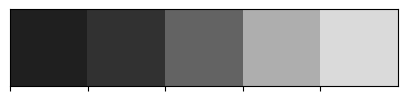

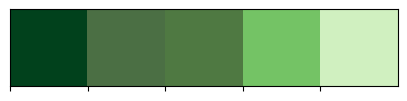

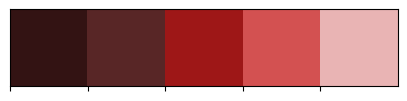

In [ ]:
# Colors will be used:
colors_dark = ["#1F1F1F", "#313131", '#636363', '#AEAEAE', '#DADADA']
colors_red = ["#331313", "#582626", '#9E1717', '#D35151', '#E9B4B4']
colors_green = ['#01411C','#4B6F44','#4F7942','#74C365','#D0F0C0']

sns.palplot(colors_dark)
sns.palplot(colors_green)
sns.palplot(colors_red)

In [ ]:
# Labels:
labels = ['glioma','meningioma','notumor', 'pituitary']

In [ ]:
IMAGE_SIZE = 224
INPUT_SHAPE = (IMAGE_SIZE, IMAGE_SIZE, 3)

CLASS_NAMES = [
    'glioma',
    'meningioma',
    'notumor',
    'pituitary'
]

## 1.1. Data loading from Medely 12k images:

In [ ]:
import zipfile
import os

# Upload dataset and unzip:
zip_path = "/content/drive/MyDrive/Brain_Tumor_Classification_Project/Epic and CSCR hospital Dataset.zip"
extract_path = "/content/brain_tumor_medely"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

print("Extracted successfully!")

Extracted successfully!


In [ ]:
train_dir = "/content/brain_tumor_medely/Epic and CSCR hospital Dataset/Train"
test_dir  = "/content/brain_tumor_medely/Epic and CSCR hospital Dataset/Test"

In [ ]:
# Data reading function:

import os
import cv2
import numpy as np
from tqdm import tqdm

def load_dataset(data_dir, labels, image_size):
    X = []
    y = []

    for label in labels:
        folder_path = os.path.join(data_dir, label)
        if not os.path.isdir(folder_path):
            raise FileNotFoundError(
                f"Class directory not found: {folder_path}"
            )
        image_files = sorted(os.listdir(folder_path))
        for filename in tqdm(
            image_files,
            desc=f"Loading {label}"
        ):
            image_path = os.path.join(folder_path, filename)
            if not os.path.isfile(image_path):
                continue
            img = cv2.imread(image_path)
            if img is None:
                print(f"Warning: Cannot read image: {image_path}")
                continue
            img = cv2.resize(
                img,
                (image_size, image_size)
            )
            X.append(img)
            y.append(label)

    if not X:
        raise ValueError(f"No valid images found in {data_dir}")

    return np.array(X), np.array(y)


# Load training and testing data
X_train_data, y_train_data = load_dataset(
    train_dir, labels, IMAGE_SIZE
)

X_test_data, y_test_data = load_dataset(
    test_dir, labels, IMAGE_SIZE
)

print(f"Training data shape: {X_train_data.shape}")
print(f"Training labels shape: {y_train_data.shape}")
print(f"Testing data shape: {X_test_data.shape}")
print(f"Testing labels shape: {y_test_data.shape}")


Loading pituitary: 100%|██████████| 626/626 [00:01<00:00, 588.50it/s]


Training data shape: (9650, 224, 224, 3)
Training labels shape: (9650,)
Testing data shape: (2414, 224, 224, 3)
Testing labels shape: (2414,)


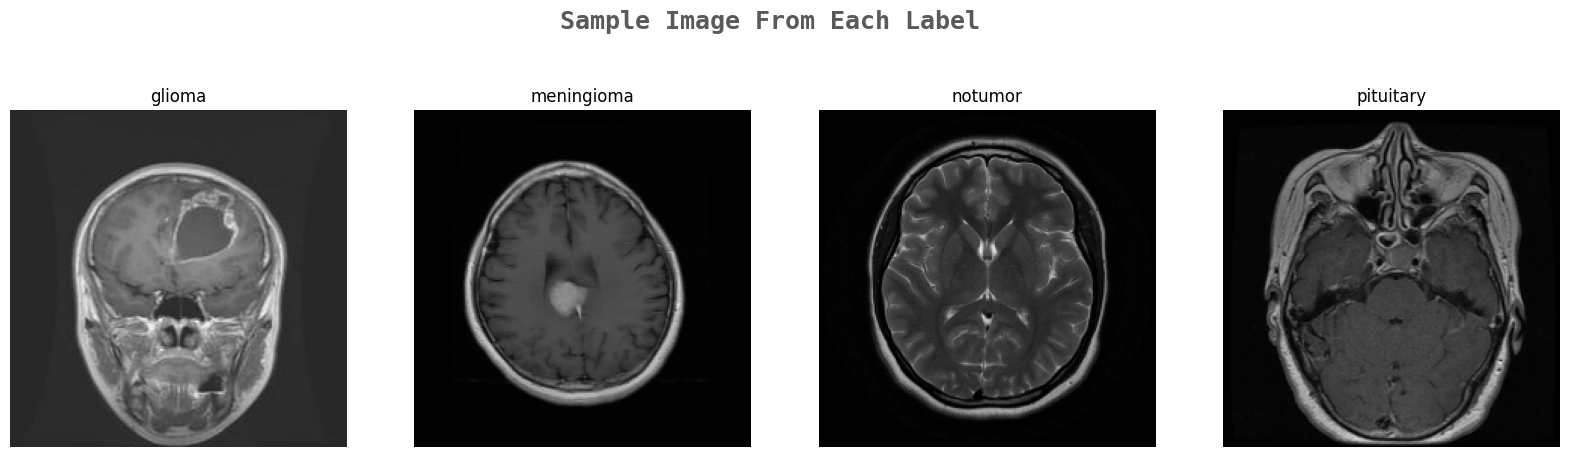

In [ ]:
# Some samples of training data:
k=0
fig, ax = plt.subplots(1,4,figsize=(20,20))
fig.text(s='Sample Image From Each Label',size=18,fontweight='bold',
             fontname='monospace',color=colors_dark[1],y=0.62,x=0.4,alpha=0.8)
for i in labels:
    j=0
    while True :
        if y_train_data[j]==i:
            ax[k].imshow(X_train_data[j])
            ax[k].set_title(y_train_data[j])
            ax[k].axis('off')
            k+=1
            break
        j+=1

### Check whether data is leaked:

In [ ]:
# Check similar images in training and testing set:
!pip install imagehash tqdm scikit-learn

import os, hashlib, csv, time
import imagehash
from sklearn.neighbors import NearestNeighbors

# CONFIG:
TRAIN_DIR = "/content/brain_tumor/Epic and CSCR hospital Dataset/Train"
TEST_DIR  = "/content/brain_tumor/Epic and CSCR hospital Dataset/Test"

# Output files
OUT_DIR = "/content/leak_check_output"
os.makedirs(OUT_DIR, exist_ok=True)
MD5_CSV = os.path.join(OUT_DIR, "md5_duplicates.csv")
PHASH_CSV = os.path.join(OUT_DIR, "phash_matches.csv")
EMBED_CSV = os.path.join(OUT_DIR, "embedding_nn_matches.csv")
SCORE_JSON = os.path.join(OUT_DIR, "leak_risk_summary.csv")

# Parameters (tuneable)
PHASH_HAMMING_THRESH = 8       # this hamming distance considered 'near-duplicate' (0.64 for 64-bit phash)
EMBED_SIMILARITY_THRESH = 0.35 # cosine distance threshold (lower means more similar). We'll use normalized euclidean ~ cosine proxy
NN_K = 1                       # nearest neighbor to check
BATCH_SIZE = 64                # embedding batchsize
IMAGE_SIZE = (224,224)         # input size for EfficientNetB0 feature extractor

# Weights for leak risk score
W_MD5 = 0.4
W_PHASH = 0.3
W_EMBED = 0.3

# Utility functions:
def md5_of_file(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

def list_images_in_dir(root):
    files=[]
    for dirpath, dirnames, filenames in os.walk(root):
        for fn in filenames:
            if fn.lower().endswith((".png",".jpg",".jpeg",".tif",".tiff","bmp")):
                files.append(os.path.join(dirpath, fn))
    return sorted(files)

# STEP 1: MD5 duplicate check:
print("STEP 1: MD5 duplicates (exact matches) ...")
t0 = time.time()
train_files = list_images_in_dir(TRAIN_DIR)
test_files  = list_images_in_dir(TEST_DIR)
print(f"Found {len(train_files)} train images, {len(test_files)} test images")

# Build map of md5 for train
train_md5 = {}
for p in tqdm(train_files, desc="Hashing train"):
    try:
        h = md5_of_file(p)
        train_md5.setdefault(h, []).append(p)
    except Exception as e:
        print("Error reading", p, e)

duplicates = []
for p in tqdm(test_files, desc="Checking test md5"):
    try:
        h = md5_of_file(p)
        if h in train_md5:
            # record each match
            for tp in train_md5[h]:
                duplicates.append({"test_path": p, "train_path": tp, "md5": h})
    except Exception as e:
        print("Error reading", p, e)

# Save duplicates
pd.DataFrame(duplicates).to_csv(MD5_CSV, index=False)
print(f"MD5 duplicates found: {len(duplicates)}. Saved to {MD5_CSV}. Time: {time.time()-t0:.1f}s")

# STEP 2: Perceptual hash (pHash) similarity
# We'll compute 64-bit pHash via imagehash.phash and measure Hamming distance
print("\nSTEP 2: Perceptual hash (pHash) similarity ...")
t0 = time.time()
# compute phashes for train and test (store as integers)
def compute_phash_map(file_list, hash_size=16):
    phash_map = {}
    for p in tqdm(file_list):
        try:
            img = Image.open(p).convert('L')  # convert to grayscale
            ph = imagehash.phash(img, hash_size=hash_size)  # 16 => 256-bit? but imagehash returns object
            # store as hex string
            phash_map[p] = ph
        except Exception as e:
            print("Error phash", p, e)
    return phash_map

train_phash = compute_phash_map(train_files, hash_size=16)
test_phash  = compute_phash_map(test_files, hash_size=16)

# Compare: for efficiency, create list of train phash values
train_items = list(train_phash.items())  # (path, phash)
train_hashes = [h for (_,h) in train_items]
train_paths = [p for (p,_) in train_items]

# For each test image, find any train image with hamming distance <= threshold
phash_matches = []
for tp, th in tqdm(test_phash.items(), desc="Comparing phash"):
    for i, tr_h in enumerate(train_hashes):
        # imagehash ImageHash supports - to get hamming distance
        dist = th - tr_h
        if dist <= PHASH_HAMMING_THRESH:
            phash_matches.append({
                "test_path": tp,
                "train_path": train_paths[i],
                "hamming": int(dist),
                "test_phash": str(th),
                "train_phash": str(tr_h)
            })
# Save
pd.DataFrame(phash_matches).to_csv(PHASH_CSV, index=False)
print(f"Perceptual-hash near-duplicates found: {len(phash_matches)}. Saved to {PHASH_CSV}. Time: {time.time()-t0:.1f}s")

# STEP 3: Embedding-based similarity (feature extractor + NN)
print("\nSTEP 3: Embedding NN similarity ...")
t0 = time.time()

# Build EfficientNetB0 feature extractor (global average pooling)
feat_model = tf.keras.applications.EfficientNetB0(
    include_top=False, weights='imagenet', pooling='avg', input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)
)

# Preprocess input helper
preprocess = tf.keras.applications.efficientnet.preprocess_input

def load_and_preprocess(path):
    img = Image.open(path).convert("RGB").resize(IMAGE_SIZE, Image.BILINEAR)
    arr = np.array(img).astype(np.float32)
    return preprocess(arr)

# Compute embeddings in batches to save memory
def compute_embeddings(file_list, batch_size=64):
    embeddings = []
    paths = []
    n = len(file_list)
    for i in tqdm(range(0, n, batch_size), desc="Embedding"):
        batch_files = file_list[i:i+batch_size]
        batch_imgs = np.stack([load_and_preprocess(p) for p in batch_files], axis=0)
        emb = feat_model.predict(batch_imgs, verbose=0)
        embeddings.append(emb)
        paths.extend(batch_files)
    embeddings = np.vstack(embeddings)
    return paths, embeddings

train_paths_e, train_emb = compute_embeddings(train_files, batch_size=BATCH_SIZE)
test_paths_e, test_emb   = compute_embeddings(test_files, batch_size=BATCH_SIZE)
print("Train emb shape:", train_emb.shape, "Test emb shape:", test_emb.shape)

# Normalize embeddings (L2) to use cosine-like distance via euclidean on normalized vectors
def l2_normalize(x):
    norms = np.linalg.norm(x, axis=1, keepdims=True) + 1e-10
    return x / norms

train_emb_n = l2_normalize(train_emb)
test_emb_n  = l2_normalize(test_emb)

# Fit nearest neighbors on train embeddings
nbrs = NearestNeighbors(n_neighbors=NN_K, algorithm='auto', metric='euclidean').fit(train_emb_n)
distances, indices = nbrs.kneighbors(test_emb_n)  # distances are euclidean between unit vectors -> related to cosine

# distances is array (num_test, K)
# convert euclidean distance between normalized vectors to cosine similarity if needed:
# cosine_sim = 1 - 0.5 * (dist^2)  (relation)
embedding_matches = []
for i, dlist in enumerate(distances):
    d0 = float(dlist[0])
    idx0 = int(indices[i][0])
    train_p = train_paths_e[idx0]
    test_p  = test_paths_e[i]
    # Convert euclidean distance to approximate cosine similarity:
    # For unit vectors u,v: ||u-v||^2 = 2 - 2*cos => cos = 1 - (||u-v||^2)/2
    cos_sim = 1.0 - (d0*d0)/2.0
    # We'll consider match if d0 <= EMBED_SIMILARITY_THRESH (euclidean) OR cos_sim >= threshold_cos
    embedding_matches.append({
        "test_path": test_p,
        "train_path": train_p,
        "euclidean": d0,
        "cosine_approx": cos_sim
    })

pd.DataFrame(embedding_matches).to_csv(EMBED_CSV, index=False)
print(f"Embedding NN matches saved to {EMBED_CSV}. Time: {time.time()-t0:.1f}s")

# STEP 4: Summarize and compute leak risk scorescore:
print("\nSTEP 4: Summarize results & compute leak risk score ...")
# counts
num_test = len(test_files)
md5_count = len(duplicates)
phash_count = len(phash_matches)

# For embedding, count how many test have euclidean distance <= threshold
embed_close = sum(1 for m in embedding_matches if m["euclidean"] <= EMBED_SIMILARITY_THRESH)

# Percentages
pct_md5 = md5_count / num_test
pct_phash = phash_count / num_test
pct_embed = embed_close / num_test

# Simple weighted score (0..1)
leak_score = W_MD5 * pct_md5 + W_PHASH * pct_phash + W_EMBED * pct_embed

summary = {
    "num_train": len(train_files),
    "num_test": num_test,
    "md5_matches": md5_count,
    "phash_matches": phash_count,
    "embed_close": embed_close,
    "pct_md5": pct_md5,
    "pct_phash": pct_phash,
    "pct_embed": pct_embed,
    "leak_score": leak_score,
    "phash_hamming_thresh": PHASH_HAMMING_THRESH,
    "embed_euclid_thresh": EMBED_SIMILARITY_THRESH
}

pd.DataFrame([summary]).to_csv(SCORE_JSON, index=False)
print("Summary saved to:", SCORE_JSON)
print(pd.DataFrame([summary]).T)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 19.5 MB/s eta 0:00:00
STEP 1: MD5 duplicates (exact matches) ...
Found 9650 train images, 2414 test images


Checking test md5: 100%|██████████| 2414/2414 [00:00<00:00, 13242.87it/s]


MD5 duplicates found: 315. Saved to /content/leak_check_output/md5_duplicates.csv. Time: 0.8s

STEP 2: Perceptual hash (pHash) similarity ...


Comparing phash: 100%|██████████| 2414/2414 [01:19<00:00, 30.29it/s]


Perceptual-hash near-duplicates found: 3212. Saved to /content/leak_check_output/phash_matches.csv. Time: 111.3s

STEP 3: Embedding NN similarity ...
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Embedding: 100%|██████████| 38/38 [00:25<00:00,  1.48it/s]


Train emb shape: (9650, 1280) Test emb shape: (2414, 1280)
Embedding NN matches saved to /content/leak_check_output/embedding_nn_matches.csv. Time: 125.1s

STEP 4: Summarize results & compute leak risk score ...
Summary saved to: /content/leak_check_output/leak_risk_summary.csv
                                0
num_train             9650.000000
num_test              2414.000000
md5_matches            315.000000
phash_matches         3212.000000
embed_close           1845.000000
pct_md5                  0.130489
pct_phash                1.330572
pct_embed                0.764292
leak_score               0.680655
phash_hamming_thresh     8.000000
embed_euclid_thresh      0.350000


**Conclusion:**
- Observations revealed 315 pairs of train-test images with matching MD5 hash values. The number of unique test images corresponding to these pairs needs to be tallied to determine the extent of the overlap.

- 3212 pairs of images in the test set are very similar to images in the train set.

→ This indicates mild data corruption or manual image augmenting.

- embed_close = 1845. Comparing embedding models → check for similar content, even with different colors, cropping, or MRI artifacts. -> 76.43% of test images have embeddings very close to the train.

### Use this dataset for training:

***=> We will combine the training and test sets of this dataset into a new training set and test the model on a different dataset.***

In [ ]:
# Function to combine training dataset:
def combine_datasets(X_train, Y_train, X_test, Y_test):
    X_train_data = np.concatenate((X_train, X_test), axis=0)
    Y_train_data = np.concatenate((Y_train, Y_test), axis=0)
    print(f"New training data shape: {X_train_data.shape}")

    X_train_data, Y_train_data = shuffle(X_train_data, Y_train_data, random_state=101)
    print(f"X_train_data shape: ", X_train_data.shape)
    print(f"Y_train_data shape: ", Y_train_data.shape)

    X_train, X_val, y_train, y_val = train_test_split(X_train_data, Y_train_data, test_size=0.2, random_state=101)
    print(f"Training set shape: {X_train.shape}")
    print(f"Validation set shape: {X_val.shape}")

    # Performing One Hot Encoding on the labels after converting it into numerical values:
    y_train_new = []
    for i in y_train:
        y_train_new.append(labels.index(i))
    y_train = y_train_new
    y_train = tf.keras.utils.to_categorical(y_train)

    y_val_new = []
    for i in y_val:
        y_val_new.append(labels.index(i))
    y_val = y_val_new
    y_val = tf.keras.utils.to_categorical(y_val)

    print(f"Y_train shape: ", y_train.shape)
    print(f"Y_val shape: ", y_val.shape)

    return X_train, y_train, X_val, y_val


In [ ]:
X_train, y_train, X_val, y_val = combine_datasets(X_train_data, y_train_data, X_test_data, y_test_data)

New training data shape: (12064, 224, 224, 3)
X_train_data shape:  (12064, 224, 224, 3)
Y_train_data shape:  (12064,)
Training set shape: (9651, 224, 224, 3)
Validation set shape: (2413, 224, 224, 3)
Y_train shape:  (9651, 4)
Y_val shape:  (2413, 4)


## 1.2. Load test data from the Simezu dataset from Huggie Face:

***Download the Simezu dataset - brain-tumor-MRI-scan to use as a test set:***

In [ ]:
!sudo apt-get install git-lfs
!git lfs install
!git clone https://huggingface.co/datasets/Simezu/brain-tumour-MRI-scan

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  git-lfs
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 3,908 kB of archives.
After this operation, 11.7 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 git-lfs amd64 3.4.1-1ubuntu0.4 [3,908 kB]
Fetched 3,908 kB in 2s (2,064 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package git-lfs.
(Reading database ... 127324 fi

In [ ]:
import os

root = "/content/brain-tumour-MRI-scan"
classes_new = sorted(os.listdir(os.path.join(root, "Training")))
print(classes_new)


['1-notumor', '2-glioma', '3-meningioma', '4-pituitary']


In [ ]:
import os
import cv2
import numpy as np
from tqdm import tqdm

new_train_dir = os.path.join(root, "Training")
new_test_dir = os.path.join(root, "Testing")

X_new_test_data = []
y_new_test_data = []
image_size = IMAGE_SIZE

label_map = {
    '1-notumor': 'notumor',
    '2-glioma': 'glioma',
    '3-meningioma': 'meningioma',
    '4-pituitary': 'pituitary'
}

# Helper function to load data from a directory
def load_images_from_directory(directory, X_list, y_list, map_dict, current_labels_list, img_size, desc_prefix):
    for folder_name in tqdm(os.listdir(directory), desc=f"{desc_prefix} {directory.split('/')[-1]}"):
        full_folder_path = os.path.join(directory, folder_name)
        if os.path.isdir(full_folder_path):
            # Ensure the folder_name is in the map_dict
            if folder_name in map_dict:
                mapped_label = map_dict[folder_name]
                for image_file in os.listdir(full_folder_path):
                    img_path = os.path.join(full_folder_path, image_file)
                    try:
                        img = cv2.imread(img_path)
                        if img is not None:
                            img = cv2.resize(img, (img_size, img_size))
                            X_list.append(img)
                            y_list.append(mapped_label)
                        else:
                            print(f"Warning: Could not read image {img_path}")
                    except Exception as e:
                        print(f"Error processing image {img_path}: {e}")

# 5. Load data from the 'Training' split of the new dataset
print(f"Loading images from new training directory: {new_train_dir}")
load_images_from_directory(new_train_dir, X_new_test_data, y_new_test_data, label_map, labels, image_size, "Loading New Train")

# 6. Load data from the 'Testing' split of the new dataset
print(f"Loading images from new testing directory: {new_test_dir}")
load_images_from_directory(new_test_dir, X_new_test_data, y_new_test_data, label_map, labels, image_size, "Loading New Test ")

# Convert lists to NumPy arrays
X_new_test_data = np.array(X_new_test_data)
y_new_test_data = np.array(y_new_test_data)

print(f"Shape of X_new_test_data: {X_new_test_data.shape}")
print(f"Shape of y_new_test_data: {y_new_test_data.shape}")

Loading images from new training directory: /content/brain-tumour-MRI-scan/Training


Loading New Train Training: 100%|██████████| 4/4 [00:12<00:00,  3.16s/it]


Loading images from new testing directory: /content/brain-tumour-MRI-scan/Testing


Loading New Test  Testing: 100%|██████████| 4/4 [00:02<00:00,  1.50it/s]


Shape of X_new_test_data: (7023, 224, 224, 3)
Shape of y_new_test_data: (7023,)


In [ ]:
X_test = X_new_test_data
y_test = y_new_test_data

print(f"Final X_test shape: {X_test.shape}")
print(f"Final y_test shape: {y_test.shape}")

Final X_test shape: (7023, 224, 224, 3)
Final y_test shape: (7023,)


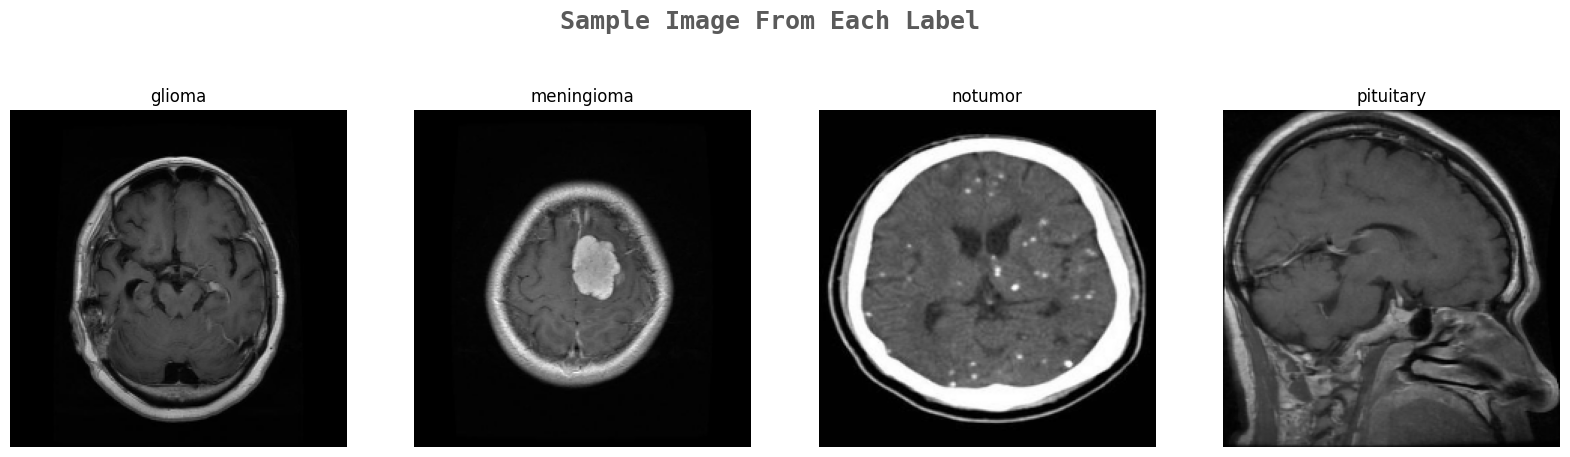

In [ ]:
# Some testing samples:
k=0
fig, ax = plt.subplots(1,4,figsize=(20,20))
fig.text(s='Sample Image From Each Label',size=18,fontweight='bold',
             fontname='monospace',color=colors_dark[1],y=0.62,x=0.4,alpha=0.8)
for i in labels:
    j=0
    while True :
        if y_test[j]==i:
            ax[k].imshow(X_test[j])
            ax[k].set_title(y_test[j])
            ax[k].axis('off')
            k+=1
            break
        j+=1

In [ ]:
# One-hot encoding cho y_test:
y_test_new = []
for i in y_test:
    y_test_new.append(labels.index(i))
y_test = y_test_new
y_test = tf.keras.utils.to_categorical(y_test)

In [ ]:
y_test.shape

(7023, 4)

### Check data leaking:

In [ ]:
# Check for data leaks between training and testing:
# Check for duplicate images in training and testing:
!pip install imagehash tqdm scikit-learn

import hashlib, csv, time
import imagehash
from sklearn.neighbors import NearestNeighbors

# CONFIG:
TRAIN_DIR = "/content/brain_tumor/Epic and CSCR hospital Dataset"
TEST_DIR  = "/content/brain-tumour-MRI-scan"

# Output files
OUT_DIR = "/content/leak_check_output2"
os.makedirs(OUT_DIR, exist_ok=True)
MD5_CSV = os.path.join(OUT_DIR, "md5_duplicates.csv")
PHASH_CSV = os.path.join(OUT_DIR, "phash_matches.csv")
EMBED_CSV = os.path.join(OUT_DIR, "embedding_nn_matches.csv")
SCORE_JSON = os.path.join(OUT_DIR, "leak_risk_summary.csv")

# Parameters (tuneable)
PHASH_HAMMING_THRESH = 8       # this hamming distance considered 'near-duplicate' (0.64 for 64-bit phash)
EMBED_SIMILARITY_THRESH = 0.35 # cosine distance threshold (lower means more similar). We'll use normalized euclidean ~ cosine proxy
NN_K = 1                       # nearest neighbor to check
BATCH_SIZE = 64                # embedding batchsize
IMAGE_SIZE = (224,224)         # input size for EfficientNetB0 feature extractor

# Weights for leak risk score
W_MD5 = 0.4
W_PHASH = 0.3
W_EMBED = 0.3

# Utility functions:
def md5_of_file(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

def list_images_in_dir(root):
    files=[]
    for dirpath, dirnames, filenames in os.walk(root):
        for fn in filenames:
            if fn.lower().endswith((".png",".jpg",".jpeg",".tif",".tiff","bmp")):
                files.append(os.path.join(dirpath, fn))
    return sorted(files)

# STEP 1: MD5 duplicate check:
print("STEP 1: MD5 duplicates (exact matches) ...")
t0 = time.time()
train_files = list_images_in_dir(TRAIN_DIR)
test_files  = list_images_in_dir(TEST_DIR)
print(f"Found {len(train_files)} train images, {len(test_files)} test images")

# Build map of md5 for train
train_md5 = {}
for p in tqdm(train_files, desc="Hashing train"):
    try:
        h = md5_of_file(p)
        train_md5.setdefault(h, []).append(p)
    except Exception as e:
        print("Error reading", p, e)

duplicates = []
for p in tqdm(test_files, desc="Checking test md5"):
    try:
        h = md5_of_file(p)
        if h in train_md5:
            # record each match
            for tp in train_md5[h]:
                duplicates.append({"test_path": p, "train_path": tp, "md5": h})
    except Exception as e:
        print("Error reading", p, e)

# Save duplicates
pd.DataFrame(duplicates).to_csv(MD5_CSV, index=False)
print(f"MD5 duplicates found: {len(duplicates)}. Saved to {MD5_CSV}. Time: {time.time()-t0:.1f}s")

# STEP 2: Perceptual hash (pHash) similarity
# We'll compute 64-bit pHash via imagehash.phash and measure Hamming distance
print("\nSTEP 2: Perceptual hash (pHash) similarity ...")
t0 = time.time()
# compute phashes for train and test (store as integers)
def compute_phash_map(file_list, hash_size=16):
    phash_map = {}
    for p in tqdm(file_list):
        try:
            img = Image.open(p).convert('L')  # convert to grayscale
            ph = imagehash.phash(img, hash_size=hash_size)  # 16 => 256-bit? but imagehash returns object
            # store as hex string
            phash_map[p] = ph
        except Exception as e:
            print("Error phash", p, e)
    return phash_map

train_phash = compute_phash_map(train_files, hash_size=16)
test_phash  = compute_phash_map(test_files, hash_size=16)

# Compare: for efficiency, create list of train phash values
train_items = list(train_phash.items())  # (path, phash)
train_hashes = [h for (_,h) in train_items]
train_paths = [p for (p,_) in train_items]

# For each test image, find any train image with hamming distance <= threshold
phash_matches = []
for tp, th in tqdm(test_phash.items(), desc="Comparing phash"):
    for i, tr_h in enumerate(train_hashes):
        # imagehash ImageHash supports - to get hamming distance
        dist = th - tr_h
        if dist <= PHASH_HAMMING_THRESH:
            phash_matches.append({
                "test_path": tp,
                "train_path": train_paths[i],
                "hamming": int(dist),
                "test_phash": str(th),
                "train_phash": str(tr_h)
            })
# Save
pd.DataFrame(phash_matches).to_csv(PHASH_CSV, index=False)
print(f"Perceptual-hash near-duplicates found: {len(phash_matches)}. Saved to {PHASH_CSV}. Time: {time.time()-t0:.1f}s")

# STEP 3: Embedding-based similarity (feature extractor + NN)
print("\nSTEP 3: Embedding NN similarity ...")
t0 = time.time()

# Build EfficientNetB0 feature extractor (global average pooling)
feat_model = tf.keras.applications.EfficientNetB0(
    include_top=False, weights='imagenet', pooling='avg', input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)
)

# Preprocess input helper
preprocess = tf.keras.applications.efficientnet.preprocess_input

def load_and_preprocess(path):
    img = Image.open(path).convert("RGB").resize(IMAGE_SIZE, Image.BILINEAR)
    arr = np.array(img).astype(np.float32)
    return preprocess(arr)

# Compute embeddings in batches to save memory
def compute_embeddings(file_list, batch_size=64):
    embeddings = []
    paths = []
    n = len(file_list)
    for i in tqdm(range(0, n, batch_size), desc="Embedding"):
        batch_files = file_list[i:i+batch_size]
        batch_imgs = np.stack([load_and_preprocess(p) for p in batch_files], axis=0)
        emb = feat_model.predict(batch_imgs, verbose=0)
        embeddings.append(emb)
        paths.extend(batch_files)
    embeddings = np.vstack(embeddings)
    return paths, embeddings

train_paths_e, train_emb = compute_embeddings(train_files, batch_size=BATCH_SIZE)
test_paths_e, test_emb   = compute_embeddings(test_files, batch_size=BATCH_SIZE)
print("Train emb shape:", train_emb.shape, "Test emb shape:", test_emb.shape)

# Normalize embeddings (L2) to use cosine-like distance via euclidean on normalized vectors
def l2_normalize(x):
    norms = np.linalg.norm(x, axis=1, keepdims=True) + 1e-10
    return x / norms

train_emb_n = l2_normalize(train_emb)
test_emb_n  = l2_normalize(test_emb)

# Fit nearest neighbors on train embeddings
nbrs = NearestNeighbors(n_neighbors=NN_K, algorithm='auto', metric='euclidean').fit(train_emb_n)
distances, indices = nbrs.kneighbors(test_emb_n)  # distances are euclidean between unit vectors -> related to cosine

# distances is array (num_test, K)
# convert euclidean distance between normalized vectors to cosine similarity if needed:
# cosine_sim = 1 - 0.5 * (dist^2)  (relation)
embedding_matches = []
for i, dlist in enumerate(distances):
    d0 = float(dlist[0])
    idx0 = int(indices[i][0])
    train_p = train_paths_e[idx0]
    test_p  = test_paths_e[i]
    # Convert euclidean distance to approximate cosine similarity:
    # For unit vectors u,v: ||u-v||^2 = 2 - 2*cos => cos = 1 - (||u-v||^2)/2
    cos_sim = 1.0 - (d0*d0)/2.0
    # We'll consider match if d0 <= EMBED_SIMILARITY_THRESH (euclidean) OR cos_sim >= threshold_cos
    embedding_matches.append({
        "test_path": test_p,
        "train_path": train_p,
        "euclidean": d0,
        "cosine_approx": cos_sim
    })

pd.DataFrame(embedding_matches).to_csv(EMBED_CSV, index=False)
print(f"Embedding NN matches saved to {EMBED_CSV}. Time: {time.time()-t0:.1f}s")

# STEP 4: Summarize and compute leak risk scorescore:
print("\nSTEP 4: Summarize results & compute leak risk score ...")
# counts
num_test = len(test_files)
md5_count = len(duplicates)
phash_count = len(phash_matches)

# For embedding, count how many test have euclidean distance <= threshold
embed_close = sum(1 for m in embedding_matches if m["euclidean"] <= EMBED_SIMILARITY_THRESH)

# Percentages
pct_md5 = md5_count / num_test
pct_phash = phash_count / num_test
pct_embed = embed_close / num_test

# Simple weighted score (0..1)
leak_score = W_MD5 * pct_md5 + W_PHASH * pct_phash + W_EMBED * pct_embed

summary = {
    "num_train": len(train_files),
    "num_test": num_test,
    "md5_matches": md5_count,
    "phash_matches": phash_count,
    "embed_close": embed_close,
    "pct_md5": pct_md5,
    "pct_phash": pct_phash,
    "pct_embed": pct_embed,
    "leak_score": leak_score,
    "phash_hamming_thresh": PHASH_HAMMING_THRESH,
    "embed_euclid_thresh": EMBED_SIMILARITY_THRESH
}

pd.DataFrame([summary]).to_csv(SCORE_JSON, index=False)
print("Summary saved to:", SCORE_JSON)
print(pd.DataFrame([summary]).T)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 11.6 MB/s eta 0:00:00
STEP 1: MD5 duplicates (exact matches) ...
Found 12064 train images, 7023 test images


Checking test md5: 100%|██████████| 7023/7023 [00:00<00:00, 15547.52it/s]


MD5 duplicates found: 6506. Saved to /content/leak_check_output2/md5_duplicates.csv. Time: 6.2s

STEP 2: Perceptual hash (pHash) similarity ...


Comparing phash: 100%|██████████| 7023/7023 [04:56<00:00, 23.71it/s]


Perceptual-hash near-duplicates found: 15745. Saved to /content/leak_check_output2/phash_matches.csv. Time: 350.4s

STEP 3: Embedding NN similarity ...


Embedding: 100%|██████████| 110/110 [00:53<00:00,  2.06it/s]


Train emb shape: (12064, 1280) Test emb shape: (7023, 1280)
Embedding NN matches saved to /content/leak_check_output2/embedding_nn_matches.csv. Time: 138.6s

STEP 4: Summarize results & compute leak risk score ...
Summary saved to: /content/leak_check_output2/leak_risk_summary.csv
                                 0
num_train             12064.000000
num_test               7023.000000
md5_matches            6506.000000
phash_matches         15745.000000
embed_close            6733.000000
pct_md5                   0.926385
pct_phash                 2.241919
pct_embed                 0.958707
leak_score                1.330742
phash_hamming_thresh      8.000000
embed_euclid_thresh       0.350000


- Therefore, this dataset is almost a copy of the old dataset and cannot be used as a test set.

## 1.3. Load a different set of 4k image data for testing:

In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Brain_Tumor_Classification_Project/Brain Tumor data.zip"
extract_path = "/content/brain_tumor_test_medely"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

print("Extracted Successfully!")

Extracted!


In [ ]:
X_train_data_medely = []
y_train_data_medely = []
X_test_data_medely = []
y_test_data_medely = []
image_size = 224

train_dir = "/content/brain_tumor_test_medely/Brain Tumor data/Training"
test_dir = "/content/brain_tumor_test_medely/Brain Tumor data/Testing"
# Load training data
for i in labels:
    folderPath = os.path.join(train_dir,i)
    for j in tqdm(os.listdir(folderPath), desc=f"Loading training {i}"):
        img = cv2.imread(os.path.join(folderPath,j))
        img = cv2.resize(img,(image_size, image_size))
        X_train_data_medely.append(img)
        y_train_data_medely.append(i)

# Load testing data
for i in labels:
    folderPath = os.path.join(test_dir,i)
    for j in tqdm(os.listdir(folderPath), desc=f"Loading testing {i}"):
        img = cv2.imread(os.path.join(folderPath,j))
        img = cv2.resize(img,(image_size,image_size))
        X_test_data_medely.append(img)
        y_test_data_medely.append(i)

X_train_data_medely = np.array(X_train_data_medely)
y_train_data_medely = np.array(y_train_data_medely)
X_test_data_medely = np.array(X_test_data_medely)
y_test_data_medely = np.array(y_test_data_medely)

print(f"Original training data shape: {X_train_data_medely.shape}")
print(f"Original testing data shape: {X_test_data_medely.shape}")

Loading testing pituitary: 100%|██████████| 300/300 [00:00<00:00, 520.90it/s]


Original training data shape: (5712, 224, 224, 3)
Original testing data shape: (1311, 224, 224, 3)


In [ ]:
# Combine these two training and test medely sets into a new test medely set:
X_test_data_medely = np.concatenate((X_test_data_medely, X_train_data_medely), axis=0)
y_test_data_medely = np.concatenate((y_test_data_medely, y_train_data_medely), axis=0)

print(f"Final testing data shape: {X_test_data_medely.shape}")

Final testing data shape: (7023, 224, 224, 3)


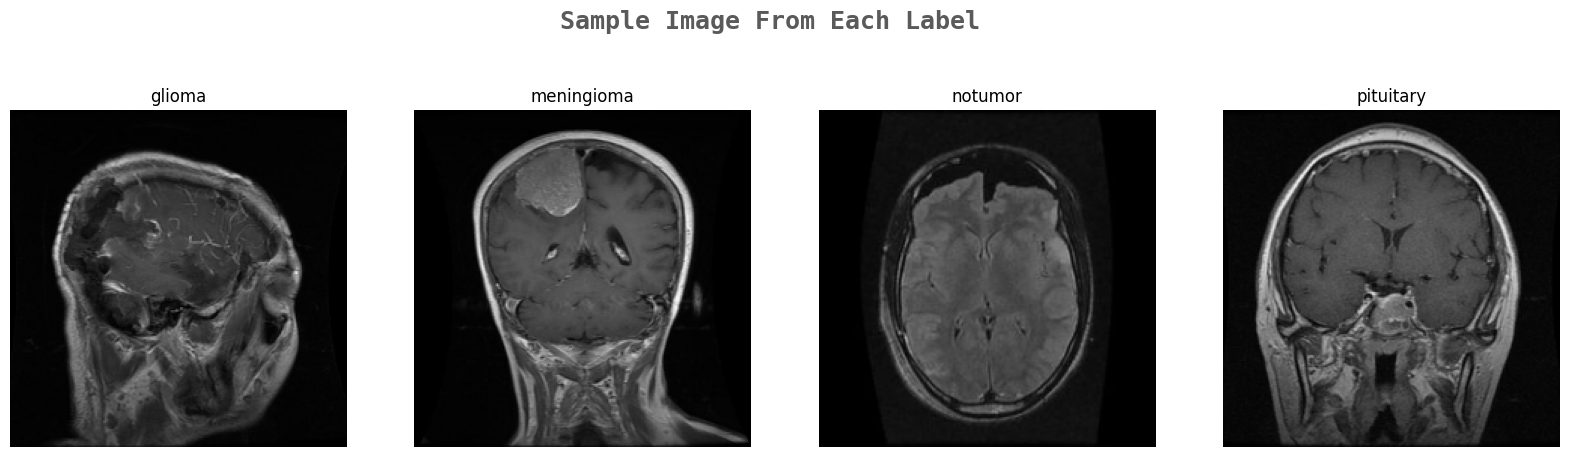

In [ ]:
# Print out some sample:
k=0
fig, ax = plt.subplots(1,4,figsize=(20,20))
fig.text(s='Sample Image From Each Label',size=18,fontweight='bold',
             fontname='monospace',color=colors_dark[1],y=0.62,x=0.4,alpha=0.8)
for i in labels:
    j=0
    while True :
        if y_test_data_medely[j]==i:
            ax[k].imshow(X_test_data_medely[j])
            ax[k].set_title(y_test_data_medely[j])
            ax[k].axis('off')
            k+=1
            break
        j+=1

In [ ]:
# One hot encoding cho y_test_data_medely:
y_test_data_medely_new = []
for i in y_test_data_medely:
    y_test_data_medely_new.append(labels.index(i))
y_test_data_medely = y_test_data_medely_new
y_test_data_medely = tf.keras.utils.to_categorical(y_test_data_medely)

### Data leak checking:

In [ ]:
!pip install imagehash tqdm scikit-learn

# CONFIG:
TRAIN_DIR = "/content/brain_tumor/Epic and CSCR hospital Dataset"
TEST_DIR  = "/content/brain_tumor_test_medely/Brain Tumor data"

# Output files
OUT_DIR = "/content/leak_check_output3"
os.makedirs(OUT_DIR, exist_ok=True)
MD5_CSV = os.path.join(OUT_DIR, "md5_duplicates.csv")
PHASH_CSV = os.path.join(OUT_DIR, "phash_matches.csv")
EMBED_CSV = os.path.join(OUT_DIR, "embedding_nn_matches.csv")
SCORE_JSON = os.path.join(OUT_DIR, "leak_risk_summary.csv")

# Parameters (tuneable)
PHASH_HAMMING_THRESH = 8       # this hamming distance considered 'near-duplicate' (0.64 for 64-bit phash)
EMBED_SIMILARITY_THRESH = 0.35 # cosine distance threshold (lower means more similar). We'll use normalized euclidean ~ cosine proxy
NN_K = 1                       # nearest neighbor to check
BATCH_SIZE = 64                # embedding batchsize
IMAGE_SIZE = (224,224)         # input size for EfficientNetB0 feature extractor

# Weights for leak risk score
W_MD5 = 0.4
W_PHASH = 0.3
W_EMBED = 0.3

# Utility functions:
def md5_of_file(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

def list_images_in_dir(root):
    files=[]
    for dirpath, dirnames, filenames in os.walk(root):
        for fn in filenames:
            if fn.lower().endswith((".png",".jpg",".jpeg",".tif",".tiff","bmp")):
                files.append(os.path.join(dirpath, fn))
    return sorted(files)

# STEP 1: MD5 duplicate check:
print("STEP 1: MD5 duplicates (exact matches) ...")
t0 = time.time()
train_files = list_images_in_dir(TRAIN_DIR)
test_files  = list_images_in_dir(TEST_DIR)
print(f"Found {len(train_files)} train images, {len(test_files)} test images")

# Build map of md5 for train
train_md5 = {}
for p in tqdm(train_files, desc="Hashing train"):
    try:
        h = md5_of_file(p)
        train_md5.setdefault(h, []).append(p)
    except Exception as e:
        print("Error reading", p, e)

duplicates = []
for p in tqdm(test_files, desc="Checking test md5"):
    try:
        h = md5_of_file(p)
        if h in train_md5:
            # record each match
            for tp in train_md5[h]:
                duplicates.append({"test_path": p, "train_path": tp, "md5": h})
    except Exception as e:
        print("Error reading", p, e)

# Save duplicates
pd.DataFrame(duplicates).to_csv(MD5_CSV, index=False)
print(f"MD5 duplicates found: {len(duplicates)}. Saved to {MD5_CSV}. Time: {time.time()-t0:.1f}s")

# STEP 2: Perceptual hash (pHash) similarity
# We'll compute 64-bit pHash via imagehash.phash and measure Hamming distance
print("\nSTEP 2: Perceptual hash (pHash) similarity ...")
t0 = time.time()
# compute phashes for train and test (store as integers)
def compute_phash_map(file_list, hash_size=16):
    phash_map = {}
    for p in tqdm(file_list):
        try:
            img = Image.open(p).convert('L')  # convert to grayscale
            ph = imagehash.phash(img, hash_size=hash_size)  # 16 => 256-bit? but imagehash returns object
            # store as hex string
            phash_map[p] = ph
        except Exception as e:
            print("Error phash", p, e)
    return phash_map

train_phash = compute_phash_map(train_files, hash_size=16)
test_phash  = compute_phash_map(test_files, hash_size=16)

# Compare: for efficiency, create list of train phash values
train_items = list(train_phash.items())  # (path, phash)
train_hashes = [h for (_,h) in train_items]
train_paths = [p for (p,_) in train_items]

# For each test image, find any train image with hamming distance <= threshold
phash_matches = []
for tp, th in tqdm(test_phash.items(), desc="Comparing phash"):
    for i, tr_h in enumerate(train_hashes):
        # imagehash ImageHash supports - to get hamming distance
        dist = th - tr_h
        if dist <= PHASH_HAMMING_THRESH:
            phash_matches.append({
                "test_path": tp,
                "train_path": train_paths[i],
                "hamming": int(dist),
                "test_phash": str(th),
                "train_phash": str(tr_h)
            })
# Save
pd.DataFrame(phash_matches).to_csv(PHASH_CSV, index=False)
print(f"Perceptual-hash near-duplicates found: {len(phash_matches)}. Saved to {PHASH_CSV}. Time: {time.time()-t0:.1f}s")

# STEP 3: Embedding-based similarity (feature extractor + NN)
print("\nSTEP 3: Embedding NN similarity ...")
t0 = time.time()

# Build EfficientNetB0 feature extractor (global average pooling)
feat_model = tf.keras.applications.EfficientNetB0(
    include_top=False, weights='imagenet', pooling='avg', input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)
)

# Preprocess input helper
preprocess = tf.keras.applications.efficientnet.preprocess_input

def load_and_preprocess(path):
    img = Image.open(path).convert("RGB").resize(IMAGE_SIZE, Image.BILINEAR)
    arr = np.array(img).astype(np.float32)
    return preprocess(arr)

# Compute embeddings in batches to save memory
def compute_embeddings(file_list, batch_size=64):
    embeddings = []
    paths = []
    n = len(file_list)
    for i in tqdm(range(0, n, batch_size), desc="Embedding"):
        batch_files = file_list[i:i+batch_size]
        batch_imgs = np.stack([load_and_preprocess(p) for p in batch_files], axis=0)
        emb = feat_model.predict(batch_imgs, verbose=0)
        embeddings.append(emb)
        paths.extend(batch_files)
    embeddings = np.vstack(embeddings)
    return paths, embeddings

train_paths_e, train_emb = compute_embeddings(train_files, batch_size=BATCH_SIZE)
test_paths_e, test_emb   = compute_embeddings(test_files, batch_size=BATCH_SIZE)
print("Train emb shape:", train_emb.shape, "Test emb shape:", test_emb.shape)

# Normalize embeddings (L2) to use cosine-like distance via euclidean on normalized vectors
def l2_normalize(x):
    norms = np.linalg.norm(x, axis=1, keepdims=True) + 1e-10
    return x / norms

train_emb_n = l2_normalize(train_emb)
test_emb_n  = l2_normalize(test_emb)

# Fit nearest neighbors on train embeddings
nbrs = NearestNeighbors(n_neighbors=NN_K, algorithm='auto', metric='euclidean').fit(train_emb_n)
distances, indices = nbrs.kneighbors(test_emb_n)  # distances are euclidean between unit vectors -> related to cosine

# distances is array (num_test, K)
# convert euclidean distance between normalized vectors to cosine similarity if needed:
# cosine_sim = 1 - 0.5 * (dist^2)  (relation)
embedding_matches = []
for i, dlist in enumerate(distances):
    d0 = float(dlist[0])
    idx0 = int(indices[i][0])
    train_p = train_paths_e[idx0]
    test_p  = test_paths_e[i]
    # Convert euclidean distance to approximate cosine similarity:
    # For unit vectors u,v: ||u-v||^2 = 2 - 2*cos => cos = 1 - (||u-v||^2)/2
    cos_sim = 1.0 - (d0*d0)/2.0
    # We'll consider match if d0 <= EMBED_SIMILARITY_THRESH (euclidean) OR cos_sim >= threshold_cos
    embedding_matches.append({
        "test_path": test_p,
        "train_path": train_p,
        "euclidean": d0,
        "cosine_approx": cos_sim
    })

pd.DataFrame(embedding_matches).to_csv(EMBED_CSV, index=False)
print(f"Embedding NN matches saved to {EMBED_CSV}. Time: {time.time()-t0:.1f}s")

# STEP 4: Summarize and compute leak risk scorescore:
print("\nSTEP 4: Summarize results & compute leak risk score ...")
# counts
num_test = len(test_files)
md5_count = len(duplicates)
phash_count = len(phash_matches)

# For embedding, count how many test have euclidean distance <= threshold
embed_close = sum(1 for m in embedding_matches if m["euclidean"] <= EMBED_SIMILARITY_THRESH)

# Percentages
pct_md5 = md5_count / num_test
pct_phash = phash_count / num_test
pct_embed = embed_close / num_test

# Simple weighted score (0..1)
leak_score = W_MD5 * pct_md5 + W_PHASH * pct_phash + W_EMBED * pct_embed

summary = {
    "num_train": len(train_files),
    "num_test": num_test,
    "md5_matches": md5_count,
    "phash_matches": phash_count,
    "embed_close": embed_close,
    "pct_md5": pct_md5,
    "pct_phash": pct_phash,
    "pct_embed": pct_embed,
    "leak_score": leak_score,
    "phash_hamming_thresh": PHASH_HAMMING_THRESH,
    "embed_euclid_thresh": EMBED_SIMILARITY_THRESH
}

pd.DataFrame([summary]).to_csv(SCORE_JSON, index=False)
print("Summary saved to:", SCORE_JSON)
print(pd.DataFrame([summary]).T)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 24.2 MB/s eta 0:00:00
STEP 1: MD5 duplicates (exact matches) ...
Found 12064 train images, 7023 test images


Checking test md5: 100%|██████████| 7023/7023 [00:00<00:00, 15968.63it/s]


MD5 duplicates found: 6506. Saved to /content/leak_check_output3/md5_duplicates.csv. Time: 2.5s

STEP 2: Perceptual hash (pHash) similarity ...


Comparing phash: 100%|██████████| 7023/7023 [04:47<00:00, 24.47it/s]


Perceptual-hash near-duplicates found: 15745. Saved to /content/leak_check_output3/phash_matches.csv. Time: 335.3s

STEP 3: Embedding NN similarity ...
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Embedding: 100%|██████████| 110/110 [00:55<00:00,  1.98it/s]


Train emb shape: (12064, 1280) Test emb shape: (7023, 1280)
Embedding NN matches saved to /content/leak_check_output3/embedding_nn_matches.csv. Time: 153.4s

STEP 4: Summarize results & compute leak risk score ...
Summary saved to: /content/leak_check_output3/leak_risk_summary.csv
                                 0
num_train             12064.000000
num_test               7023.000000
md5_matches            6506.000000
phash_matches         15745.000000
embed_close            6733.000000
pct_md5                   0.926385
pct_phash                 2.241919
pct_embed                 0.958707
leak_score                1.330742
phash_hamming_thresh      8.000000
embed_euclid_thresh       0.350000


- So, this dataset is just a copy of the training dataset and cannot be used for testing.

## 1.4. Final option: Filter the data that does not overlap with the training set in this dataset of approximately 7,000 images to use as test data:

### Filtering data:

In [ ]:
# INSTALL
!pip install imagehash tqdm scikit-learn

# IMPORT
import shutil

# CONFIG
TRAIN_DIR = "/content/brain_tumor_medely/Epic and CSCR hospital Dataset"
TEST_DIRS = [
    "/content/brain_tumor_test_medely/Brain Tumor data/Training",
    "/content/brain_tumor_test_medely/Brain Tumor data/Testing"
]

OUT_DIR   = "/content/final_test_clean"

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

PHASH_THRESH = 8
EMBED_THRESH = 0.35
IMG_SIZE = (224,224)
BATCH = 64

os.makedirs(OUT_DIR, exist_ok=True)
for c in CLASSES:
    os.makedirs(os.path.join(OUT_DIR, c), exist_ok=True)

# UTILS
def list_images(root):
    files = []
    for dp,_,fns in os.walk(root):
        for f in fns:
            if f.lower().endswith((".png",".jpg",".jpeg")):
                files.append(os.path.join(dp,f))
    return files

def md5(path):
    h = hashlib.md5()
    with open(path,"rb") as f:
        for c in iter(lambda: f.read(8192), b""):
            h.update(c)
    return h.hexdigest()

# STEP 1: TRAIN HASH
print("🔹 Hashing TRAIN images")
train_imgs = list_images(TRAIN_DIR)

train_md5 = {}
train_phash = {}
for p in tqdm(train_imgs):
    train_md5[md5(p)] = p
    train_phash[p] = imagehash.phash(Image.open(p).convert("L"))

# STEP 2: TRAIN EMBEDDING
print("🔹 Computing TRAIN embeddings")

model = tf.keras.applications.EfficientNetB0(
    include_top=False, pooling="avg", weights="imagenet",
    input_shape=(224,224,3)
)
pre = tf.keras.applications.efficientnet.preprocess_input

def load_img(p):
    return pre(np.array(Image.open(p).convert("RGB").resize(IMG_SIZE)))

train_emb = []
for i in tqdm(range(0,len(train_imgs),BATCH)):
    batch = np.stack([load_img(p) for p in train_imgs[i:i+BATCH]])
    train_emb.append(model.predict(batch, verbose=0))
train_emb = np.vstack(train_emb)

train_emb /= np.linalg.norm(train_emb, axis=1, keepdims=True)

nn = NearestNeighbors(n_neighbors=1, metric="euclidean")
nn.fit(train_emb)

# STEP 3: FILTER TEST
print("🔹 Filtering TEST candidate dataset")

kept = {c:0 for c in CLASSES}
removed = {c:0 for c in CLASSES}

for cls in CLASSES:
    test_imgs = []
    for base in TEST_DIRS:
        test_imgs += list_images(os.path.join(base, cls))

    for p in tqdm(test_imgs, desc=f"Filtering {cls}"):

        # MD5
        if md5(p) in train_md5:
            removed[cls]+=1
            continue

        # pHash
        ph = imagehash.phash(Image.open(p).convert("L"))
        if any((ph - tph) <= PHASH_THRESH for tph in train_phash.values()):
            removed[cls]+=1
            continue

        # Embedding
        emb = model.predict(np.expand_dims(load_img(p),0), verbose=0)
        emb /= np.linalg.norm(emb)
        dist,_ = nn.kneighbors(emb)
        if dist[0][0] <= EMBED_THRESH:
            removed[cls]+=1
            continue

        # KEEP
        shutil.copy(p, os.path.join(OUT_DIR, cls, os.path.basename(p)))
        kept[cls]+=1

# SUMMARY
print("\n✅ FILTER DONE")
for c in CLASSES:
    print(f"{c:10s} | kept: {kept[c]:4d} | removed: {removed[c]:4d}")


🔹 Hashing TRAIN images


100%|██████████| 12064/12064 [00:31<00:00, 383.23it/s]


🔹 Computing TRAIN embeddings


100%|██████████| 189/189 [01:25<00:00,  2.20it/s]


🔹 Filtering TEST candidate dataset


Filtering pituitary: 100%|██████████| 1757/1757 [00:15<00:00, 112.86it/s]


✅ FILTER DONE
glioma     | kept:   49 | removed: 1572
meningioma | kept:   13 | removed: 1632
notumor    | kept:   20 | removed: 1980
pituitary  | kept:    9 | removed: 1748


In [ ]:
# Save final test set into drive:
DRIVE_OUT = "/content/drive/MyDrive/Brain_Tumor_Classification_Project/BrainTumor_FinalTest_CLEAN"

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

for c in CLASSES:
    os.makedirs(os.path.join(DRIVE_OUT, c), exist_ok=True)

OUT_DIR = "/content/final_test_clean"

import shutil
from tqdm import tqdm

for c in CLASSES:
    src = os.path.join(OUT_DIR, c)
    dst = os.path.join(DRIVE_OUT, c)

    files = os.listdir(src)
    for f in tqdm(files, desc=f"Copying {c}"):
        shutil.copy(
            os.path.join(src, f),
            os.path.join(dst, f)
        )

for c in CLASSES:
    n = len(os.listdir(os.path.join(DRIVE_OUT, c)))
    print(f"{c:12s}: {n}")

Copying pituitary: 100%|██████████| 9/9 [00:00<00:00, 136.85it/s]

glioma      : 49
meningioma  : 13
notumor     : 20
pituitary   : 9


In [ ]:
# Check for leaks between training and testing:
# Check for image duplication in training and testing:
!pip install imagehash tqdm scikit-learn

# CONFIG:
TRAIN_DIR = "/content/brain_tumor_medely/Epic and CSCR hospital Dataset"
TEST_DIR  = "/content/final_test_clean"

# Output files
OUT_DIR = "/content/leak_check_output_final"
os.makedirs(OUT_DIR, exist_ok=True)
MD5_CSV = os.path.join(OUT_DIR, "md5_duplicates.csv")
PHASH_CSV = os.path.join(OUT_DIR, "phash_matches.csv")
EMBED_CSV = os.path.join(OUT_DIR, "embedding_nn_matches.csv")
SCORE_JSON = os.path.join(OUT_DIR, "leak_risk_summary.csv")

# Parameters (tuneable)
PHASH_HAMMING_THRESH = 8       # this hamming distance considered 'near-duplicate' (0.64 for 64-bit phash)
EMBED_SIMILARITY_THRESH = 0.35 # cosine distance threshold (lower means more similar). We'll use normalized euclidean ~ cosine proxy
NN_K = 1                       # nearest neighbor to check
BATCH_SIZE = 64                # embedding batchsize
IMAGE_SIZE = (224,224)         # input size for EfficientNetB0 feature extractor

# Weights for leak risk score
W_MD5 = 0.4
W_PHASH = 0.3
W_EMBED = 0.3

# Utility functions:
def md5_of_file(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

def list_images_in_dir(root):
    files=[]
    for dirpath, dirnames, filenames in os.walk(root):
        for fn in filenames:
            if fn.lower().endswith((".png",".jpg",".jpeg",".tif",".tiff","bmp")):
                files.append(os.path.join(dirpath, fn))
    return sorted(files)

# STEP 1: MD5 duplicate check:
print("STEP 1: MD5 duplicates (exact matches) ...")
t0 = time.time()
train_files = list_images_in_dir(TRAIN_DIR)
test_files  = list_images_in_dir(TEST_DIR)
print(f"Found {len(train_files)} train images, {len(test_files)} test images")

# Build map of md5 for train
train_md5 = {}
for p in tqdm(train_files, desc="Hashing train"):
    try:
        h = md5_of_file(p)
        train_md5.setdefault(h, []).append(p)
    except Exception as e:
        print("Error reading", p, e)

duplicates = []
for p in tqdm(test_files, desc="Checking test md5"):
    try:
        h = md5_of_file(p)
        if h in train_md5:
            # record each match
            for tp in train_md5[h]:
                duplicates.append({"test_path": p, "train_path": tp, "md5": h})
    except Exception as e:
        print("Error reading", p, e)

# Save duplicates
pd.DataFrame(duplicates).to_csv(MD5_CSV, index=False)
print(f"MD5 duplicates found: {len(duplicates)}. Saved to {MD5_CSV}. Time: {time.time()-t0:.1f}s")

# STEP 2: Perceptual hash (pHash) similarity
# We'll compute 64-bit pHash via imagehash.phash and measure Hamming distance
print("\nSTEP 2: Perceptual hash (pHash) similarity ...")
t0 = time.time()
# compute phashes for train and test (store as integers)
def compute_phash_map(file_list, hash_size=16):
    phash_map = {}
    for p in tqdm(file_list):
        try:
            img = Image.open(p).convert('L')  # convert to grayscale
            ph = imagehash.phash(img, hash_size=hash_size)  # 16 => 256-bit? but imagehash returns object
            # store as hex string
            phash_map[p] = ph
        except Exception as e:
            print("Error phash", p, e)
    return phash_map

train_phash = compute_phash_map(train_files, hash_size=16)
test_phash  = compute_phash_map(test_files, hash_size=16)

# Compare: for efficiency, create list of train phash values
train_items = list(train_phash.items())  # (path, phash)
train_hashes = [h for (_,h) in train_items]
train_paths = [p for (p,_) in train_items]

# For each test image, find any train image with hamming distance <= threshold
phash_matches = []
for tp, th in tqdm(test_phash.items(), desc="Comparing phash"):
    for i, tr_h in enumerate(train_hashes):
        # imagehash ImageHash supports - to get hamming distance
        dist = th - tr_h
        if dist <= PHASH_HAMMING_THRESH:
            phash_matches.append({
                "test_path": tp,
                "train_path": train_paths[i],
                "hamming": int(dist),
                "test_phash": str(th),
                "train_phash": str(tr_h)
            })
# Save
pd.DataFrame(phash_matches).to_csv(PHASH_CSV, index=False)
print(f"Perceptual-hash near-duplicates found: {len(phash_matches)}. Saved to {PHASH_CSV}. Time: {time.time()-t0:.1f}s")

# STEP 3: Embedding-based similarity (feature extractor + NN)
print("\nSTEP 3: Embedding NN similarity ...")
t0 = time.time()

# Build EfficientNetB0 feature extractor (global average pooling)
feat_model = tf.keras.applications.EfficientNetB0(
    include_top=False, weights='imagenet', pooling='avg', input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)
)

# Preprocess input helper
preprocess = tf.keras.applications.efficientnet.preprocess_input

def load_and_preprocess(path):
    img = Image.open(path).convert("RGB").resize(IMAGE_SIZE, Image.BILINEAR)
    arr = np.array(img).astype(np.float32)
    return preprocess(arr)

# Compute embeddings in batches to save memory
def compute_embeddings(file_list, batch_size=64):
    embeddings = []
    paths = []
    n = len(file_list)
    for i in tqdm(range(0, n, batch_size), desc="Embedding"):
        batch_files = file_list[i:i+batch_size]
        batch_imgs = np.stack([load_and_preprocess(p) for p in batch_files], axis=0)
        emb = feat_model.predict(batch_imgs, verbose=0)
        embeddings.append(emb)
        paths.extend(batch_files)
    embeddings = np.vstack(embeddings)
    return paths, embeddings

train_paths_e, train_emb = compute_embeddings(train_files, batch_size=BATCH_SIZE)
test_paths_e, test_emb   = compute_embeddings(test_files, batch_size=BATCH_SIZE)
print("Train emb shape:", train_emb.shape, "Test emb shape:", test_emb.shape)

# Normalize embeddings (L2) to use cosine-like distance via euclidean on normalized vectors
def l2_normalize(x):
    norms = np.linalg.norm(x, axis=1, keepdims=True) + 1e-10
    return x / norms

train_emb_n = l2_normalize(train_emb)
test_emb_n  = l2_normalize(test_emb)

# Fit nearest neighbors on train embeddings
nbrs = NearestNeighbors(n_neighbors=NN_K, algorithm='auto', metric='euclidean').fit(train_emb_n)
distances, indices = nbrs.kneighbors(test_emb_n)  # distances are euclidean between unit vectors -> related to cosine

# distances is array (num_test, K)
# convert euclidean distance between normalized vectors to cosine similarity if needed:
# cosine_sim = 1 - 0.5 * (dist^2)  (relation)
embedding_matches = []
for i, dlist in enumerate(distances):
    d0 = float(dlist[0])
    idx0 = int(indices[i][0])
    train_p = train_paths_e[idx0]
    test_p  = test_paths_e[i]
    # Convert euclidean distance to approximate cosine similarity:
    # For unit vectors u,v: ||u-v||^2 = 2 - 2*cos => cos = 1 - (||u-v||^2)/2
    cos_sim = 1.0 - (d0*d0)/2.0
    # We'll consider match if d0 <= EMBED_SIMILARITY_THRESH (euclidean) OR cos_sim >= threshold_cos
    embedding_matches.append({
        "test_path": test_p,
        "train_path": train_p,
        "euclidean": d0,
        "cosine_approx": cos_sim
    })

pd.DataFrame(embedding_matches).to_csv(EMBED_CSV, index=False)
print(f"Embedding NN matches saved to {EMBED_CSV}. Time: {time.time()-t0:.1f}s")

# STEP 4: Summarize and compute leak risk scorescore:
print("\nSTEP 4: Summarize results & compute leak risk score ...")
# counts
num_test = len(test_files)
md5_count = len(duplicates)
phash_count = len(phash_matches)

# For embedding, count how many test have euclidean distance <= threshold
embed_close = sum(1 for m in embedding_matches if m["euclidean"] <= EMBED_SIMILARITY_THRESH)

# Percentages
pct_md5 = md5_count / num_test
pct_phash = phash_count / num_test
pct_embed = embed_close / num_test

# Simple weighted score (0..1)
leak_score = W_MD5 * pct_md5 + W_PHASH * pct_phash + W_EMBED * pct_embed

summary = {
    "num_train": len(train_files),
    "num_test": num_test,
    "md5_matches": md5_count,
    "phash_matches": phash_count,
    "embed_close": embed_close,
    "pct_md5": pct_md5,
    "pct_phash": pct_phash,
    "pct_embed": pct_embed,
    "leak_score": leak_score,
    "phash_hamming_thresh": PHASH_HAMMING_THRESH,
    "embed_euclid_thresh": EMBED_SIMILARITY_THRESH
}

pd.DataFrame([summary]).to_csv(SCORE_JSON, index=False)
print("Summary saved to:", SCORE_JSON)
print(pd.DataFrame([summary]).T)


STEP 1: MD5 duplicates (exact matches) ...
Found 12064 train images, 91 test images


Checking test md5: 100%|██████████| 91/91 [00:00<00:00, 6220.87it/s]


MD5 duplicates found: 0. Saved to /content/leak_check_output_final/md5_duplicates.csv. Time: 1.9s

STEP 2: Perceptual hash (pHash) similarity ...


Comparing phash: 100%|██████████| 91/91 [00:03<00:00, 28.38it/s]


Perceptual-hash near-duplicates found: 0. Saved to /content/leak_check_output_final/phash_matches.csv. Time: 38.5s

STEP 3: Embedding NN similarity ...


Embedding: 100%|██████████| 2/2 [00:13<00:00,  6.54s/it]


Train emb shape: (12064, 1280) Test emb shape: (91, 1280)
Embedding NN matches saved to /content/leak_check_output_final/embedding_nn_matches.csv. Time: 90.6s

STEP 4: Summarize results & compute leak risk score ...
Summary saved to: /content/leak_check_output_final/leak_risk_summary.csv
                                 0
num_train             12064.000000
num_test                 91.000000
md5_matches               0.000000
phash_matches             0.000000
embed_close               1.000000
pct_md5                   0.000000
pct_phash                 0.000000
pct_embed                 0.010989
leak_score                0.003297
phash_hamming_thresh      8.000000
embed_euclid_thresh       0.350000


### Reload the new test set:

In [ ]:
# Upload dataset and unzip:
zip_path = "/content/drive/MyDrive/Brain_Tumor_Classification_Project/BrainTumor_FinalTest_CLEAN-20251213T130943Z-1-001.zip"
extract_path = "/content/brain_tumor_test_clean"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

print("Extracted successfully!")

In [ ]:
test_dir = "/content/drive/MyDrive/Brain_Tumor_Classification_Project/BrainTumor_FinalTest_CLEAN"

X_test, y_test = load_dataset(test_dir, labels, IMAGE_SIZE)

print(f"Test set shape: {X_test.shape}")
print(f"Test labels shape: {y_test.shape}")

Loading pituitary: 100%|██████████| 9/9 [00:03<00:00,  2.50it/s]

Test set shape: (91, 224, 224, 3)
Test labels shape: (91,)


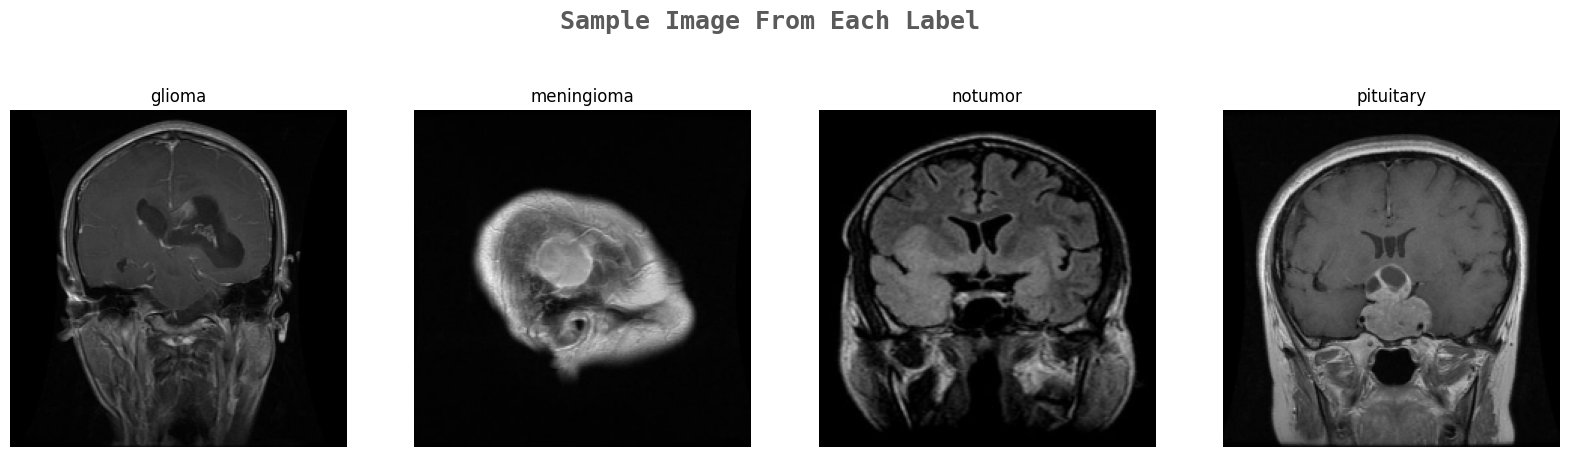

In [ ]:
# Some testing samples:
k=0
fig, ax = plt.subplots(1,4,figsize=(20,20))
fig.text(s='Sample Image From Each Label',size=18,fontweight='bold',
             fontname='monospace',color=colors_dark[1],y=0.62,x=0.4,alpha=0.8)
for i in labels:
    j=0
    while True :
        if y_test[j]==i:
            ax[k].imshow(X_test[j])
            ax[k].set_title(y_test[j])
            ax[k].axis('off')
            k+=1
            break
        j+=1

# EXPERIMENT:

# 2. Model EfficientNetB0:

## 2.1. Load and build model EfficientNetB0:

In [ ]:
from tensorflow.keras import layers, Model

# Unified Classification Head:
def build_classifier_head(
    feature_map,
    num_classes=4,
    dropout_rate=0.3,
    dense_units=256
):
    x = layers.GlobalAveragePooling2D()(feature_map) # The pooling layer averages only the channels instead of flattening the entire area to reduce overfitting.
    x = layers.Dropout(dropout_rate)(x) # Drop-out with a rate of 0.3 helps reduce overfitting.
    x = layers.Dense(
        dense_units,
        activation="relu"
    )(x) # Dense layer with nonlinear activation functions help models learn to perform better.
    x = layers.BatchNormalization()(x) # Stabilize the gradient and increase accuracy.
    x = layers.Dropout(dropout_rate)(x)  # Add a final dropout to reduce overfitting.

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return outputs

In [ ]:
from tensorflow.keras.applications import EfficientNetB0

def build_effnetb0(input_shape=INPUT_SHAPE, num_classes=4):
    inputs = layers.Input(shape=input_shape)

    backbone = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    backbone.trainable = False

    outputs = build_classifier_head(
        backbone.output,
        num_classes=num_classes
    )

    return Model(inputs, outputs, name="EfficientNetB0")

In [ ]:
effnetb0 = build_effnetb0(input_shape=INPUT_SHAPE, num_classes=4)
effnetb0.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,379,559 (16.71 MB)

 Trainable params: 329,476 (1.26 MB)

 Non-trainable params: 4,050,083 (15.45 MB)

In [ ]:
# compile model:
effnetb0.compile(loss='categorical_crossentropy',optimizer = 'Adam', metrics= ['accuracy'])

##  2.2. Fine-tunning model EfficientNetB0:

In [ ]:
tensorboard_b0 = TensorBoard(
    log_dir='log_b0',
)

checkpoint_b0 = ModelCheckpoint(
    "effnetb0_best.h5",
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

reduce_lr_b0 = ReduceLROnPlateau(
    monitor='val_loss', # Monitor val_loss to reduce learning rate
    factor=0.2, # lr reduction level
    patience=3, # Wait for val_acc improvement
    min_delta=1e-4, # Minimum acceptable improvement level
    min_lr=1e-7, # Minimum lr value to be reduced
    verbose=1
)


In [ ]:
# Model training:
history_b0 = effnetb0.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, verbose=1, batch_size=32,
                   callbacks=[tensorboard_b0,checkpoint_b0,reduce_lr_b0])

Epoch 1/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.7115 - loss: 0.8305
Epoch 1: val_loss improved from None to 0.28910, saving model to effnetb0_best.h5



Epoch 1: finished saving model to effnetb0_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 81s 161ms/step - accuracy: 0.7726 - loss: 0.6280 - val_accuracy: 0.8881 - val_loss: 0.2891 - learning_rate: 0.0010
Epoch 2/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8376 - loss: 0.4291
Epoch 2: val_loss did not improve from 0.28910
302/302 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.8393 - loss: 0.4250 - val_accuracy: 0.8645 - val_loss: 0.3158 - learning_rate: 0.0010
Epoch 3/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8520 - loss: 0.3827
Epoch 3: val_loss improved from 0.28910 to 0.22215, saving model to effnetb0_best.h5



Epoch 3: finished saving model to effnetb0_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.8562 - loss: 0.3783 - val_accuracy: 0.9109 - val_loss: 0.2221 - learning_rate: 0.0010
Epoch 4/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8666 - loss: 0.3620
Epoch 4: val_loss improved from 0.22215 to 0.21068, saving model to effnetb0_best.h5



Epoch 4: finished saving model to effnetb0_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.8703 - loss: 0.3459 - val_accuracy: 0.9237 - val_loss: 0.2107 - learning_rate: 0.0010
Epoch 5/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8714 - loss: 0.3337
Epoch 5: val_loss improved from 0.21068 to 0.19821, saving model to effnetb0_best.h5



Epoch 5: finished saving model to effnetb0_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.8761 - loss: 0.3299 - val_accuracy: 0.9283 - val_loss: 0.1982 - learning_rate: 0.0010
Epoch 6/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8855 - loss: 0.3177
Epoch 6: val_loss did not improve from 0.19821
302/302 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.8863 - loss: 0.3063 - val_accuracy: 0.9254 - val_loss: 0.2178 - learning_rate: 0.0010
Epoch 7/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8817 - loss: 0.3046
Epoch 7: val_loss improved from 0.19821 to 0.16360, saving model to effnetb0_best.h5


...


Epoch 24: finished saving model to effnetb0_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 17s 58ms/step - accuracy: 0.9440 - loss: 0.1582 - val_accuracy: 0.9731 - val_loss: 0.0830 - learning_rate: 2.0000e-04
Epoch 25/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9369 - loss: 0.1674
Epoch 25: val_loss improved from 0.08301 to 0.08136, saving model to effnetb0_best.h5



Epoch 25: finished saving model to effnetb0_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 17s 56ms/step - accuracy: 0.9391 - loss: 0.1602 - val_accuracy: 0.9726 - val_loss: 0.0814 - learning_rate: 2.0000e-04
Epoch 26/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9473 - loss: 0.1463
Epoch 26: val_loss improved from 0.08136 to 0.07988, saving model to effnetb0_best.h5



Epoch 26: finished saving model to effnetb0_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 18s 50ms/step - accuracy: 0.9453 - loss: 0.1513 - val_accuracy: 0.9710 - val_loss: 0.0799 - learning_rate: 2.0000e-04
Epoch 27/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9430 - loss: 0.1563
Epoch 27: val_loss improved from 0.07988 to 0.07821, saving model to effnetb0_best.h5



Epoch 27: finished saving model to effnetb0_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 15s 51ms/step - accuracy: 0.9420 - loss: 0.1579 - val_accuracy: 0.9743 - val_loss: 0.0782 - learning_rate: 2.0000e-04
Epoch 28/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9406 - loss: 0.1673
Epoch 28: val_loss did not improve from 0.07821
302/302 ━━━━━━━━━━━━━━━━━━━━ 15s 48ms/step - accuracy: 0.9407 - loss: 0.1648 - val_accuracy: 0.9743 - val_loss: 0.0809 - learning_rate: 2.0000e-04
Epoch 29/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9410 - loss: 0.1499
Epoch 29: val_loss improved from 0.07821 to 0.07563, saving model to effnetb0_best.h5



Epoch 29: finished saving model to effnetb0_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - accuracy: 0.9404 - loss: 0.1570 - val_accuracy: 0.9731 - val_loss: 0.0756 - learning_rate: 2.0000e-04
Epoch 30/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9433 - loss: 0.1531
Epoch 30: val_loss did not improve from 0.07563
302/302 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.9417 - loss: 0.1552 - val_accuracy: 0.9739 - val_loss: 0.0763 - learning_rate: 2.0000e-04


In [ ]:
from warnings import filterwarnings

# Function print out training session:
def plot_training_history(model, model_name):
    filterwarnings('ignore')

    train_acc = model.history['accuracy']
    train_loss = model.history['loss']
    val_acc = model.history['val_accuracy']
    val_loss = model.history['val_loss']

    epochs = range(1, len(train_acc) + 1)

    fig, ax = plt.subplots(1, 2, figsize=(14, 7))

    # Model name
    fig.suptitle(
        f'Training History: {model_name}',
        fontsize=20,
        fontweight='bold',
        y=1.03
    )

    # Accuracy plot
    ax[0].plot(
        epochs, train_acc,
        marker='o',
        markerfacecolor=colors_green[2],
        color=colors_green[3],
        label='Training Accuracy'
    )
    ax[0].plot(
        epochs, val_acc,
        marker='o',
        markerfacecolor=colors_red[2],
        color=colors_red[3],
        label='Validation Accuracy'
    )
    ax[0].legend(frameon=False)
    ax[0].set_xlabel('Epochs')
    ax[0].set_ylabel('Accuracy')
    ax[0].set_title('Training and Validation Accuracy')

    # Loss plot
    ax[1].plot(
        epochs, train_loss,
        marker='o',
        markerfacecolor=colors_green[2],
        color=colors_green[3],
        label='Training Loss'
    )
    ax[1].plot(
        epochs, val_loss,
        marker='o',
        markerfacecolor=colors_red[2],
        color=colors_red[3],
        label='Validation Loss'
    )
    ax[1].legend(frameon=False)
    ax[1].set_xlabel('Epochs')
    ax[1].set_ylabel('Loss')
    ax[1].set_title('Training and Validation Loss')

    sns.despine()
    plt.tight_layout()
    plt.show()

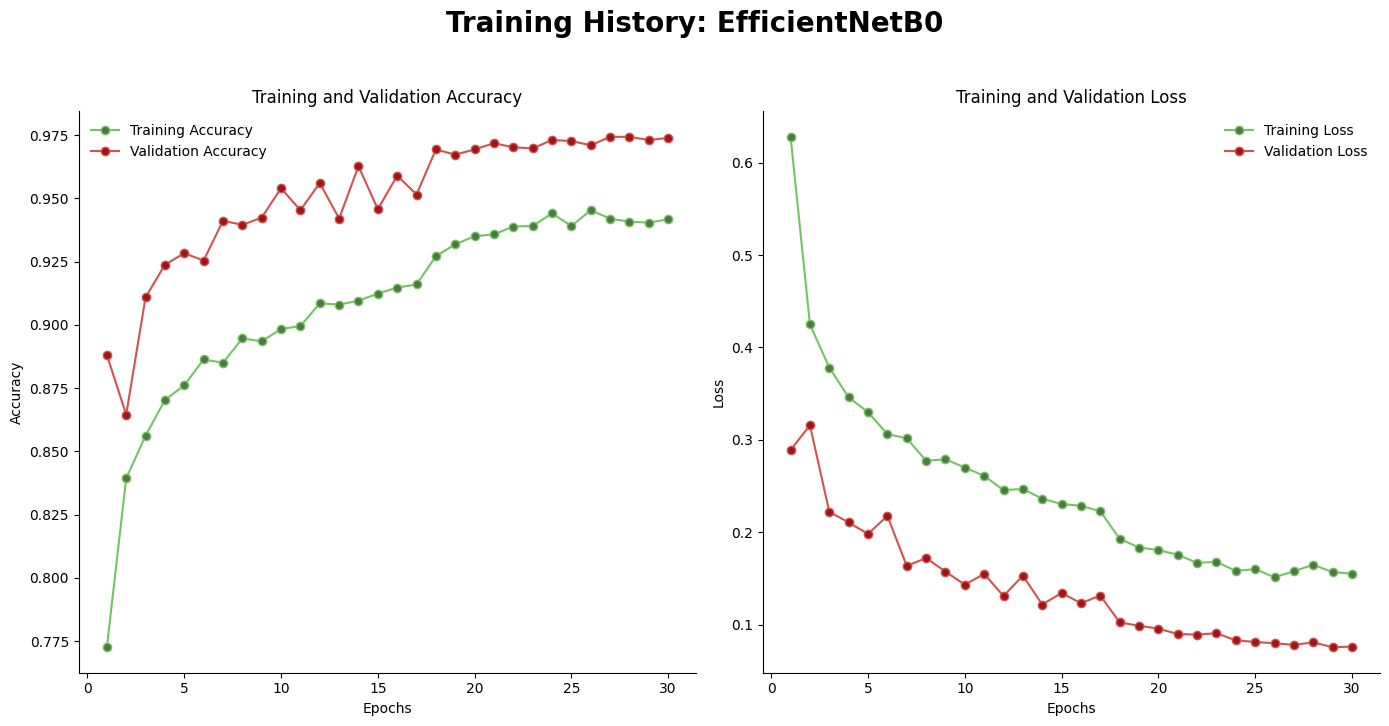

In [ ]:
# Print out traning session:
plot_training_history(history_b0, "EfficientNetB0")

## 2.3. Evaluate the model on the test set:

In [ ]:

n_samples = len(X_test)
n_classes = len(labels)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


def evaluate_model(
    model,
    X_test,
    y_test,
    model_name="Model",
    class_names=None,
    no_tumor_label="notumor",
    batch_size=32,
    plot_cm=True
):
    """
    Evaluate a trained Keras classification model.

    Includes:
    - Inference time and throughput
    - Accuracy, Precision, Recall, F1-score
    - Tumor-to-No-Tumor False Negative Rate (FNR)
    - Classification report and confusion matrix

    class_names must follow the exact output order of the model.
    y_test can contain integer labels or one-hot encoded labels.
    """

    # 1. Validate inputs
    if len(X_test) == 0:
        raise ValueError("X_test must not be empty.")

    if len(X_test) != len(y_test):
        raise ValueError("X_test and y_test must have equal lengths.")

    if batch_size < 1:
        raise ValueError("batch_size must be >= 1.")

    if class_names is None:
        raise ValueError(
            "Provide class_names in the exact model output order."
        )

    if no_tumor_label not in class_names:
        raise ValueError(
            f"'{no_tumor_label}' is not present in class_names."
        )


    # 2. Convert ground-truth labels to class indices
    y_test = np.asarray(y_test)

    if y_test.ndim > 1 and y_test.shape[-1] > 1:
        # One-hot encoded labels
        y_true = np.argmax(y_test, axis=-1)

    else:
        # String labels or integer labels
        y_test_flat = y_test.reshape(-1)

        if np.issubdtype(y_test_flat.dtype, np.number):
            y_true = y_test_flat.astype(int)
        else:
            # Convert string labels to indices using class_names
            label_to_index = {
                name: idx for idx, name in enumerate(class_names)
            }

            unknown_labels = set(y_test_flat) - set(label_to_index)

            if unknown_labels:
                raise ValueError(
                    f"Unknown labels in y_test: {unknown_labels}"
                )

            y_true = np.array([
                label_to_index[label] for label in y_test_flat
            ])


    # 3. Warm-up before timing
    warmup_size = min(batch_size, n_samples)

    _ = model.predict(
        X_test[:warmup_size],
        batch_size=batch_size,
        verbose=0
    )

    # 4. Measure prediction time
    start_time = time.perf_counter()

    y_prob = model.predict(
        X_test,
        batch_size=batch_size,
        verbose=0
    )

    total_time = time.perf_counter() - start_time

    y_pred = np.argmax(y_prob, axis=-1)

    if len(y_pred) != n_samples:
        raise ValueError("Prediction count does not match test sample count.")

    avg_time_ms = total_time / n_samples * 1000
    throughput = n_samples / total_time if total_time > 0 else float("inf")

    # 5. Overall classification metrics
    accuracy = accuracy_score(y_true, y_pred)

    precision_macro = precision_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    recall_macro = recall_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    f1_macro = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    precision_weighted = precision_score(
        y_true, y_pred, average="weighted", zero_division=0
    )
    recall_weighted = recall_score(
        y_true, y_pred, average="weighted", zero_division=0
    )
    f1_weighted = f1_score(
        y_true, y_pred, average="weighted", zero_division=0
    )

    # 6. Confusion matrix with fixed class order
    labels = list(range(n_classes))

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels
    )

    # 7. Tumor-to-No-Tumor FNR
    no_tumor_idx = class_names.index(no_tumor_label)

    tumor_indices = [
        i for i in labels
        if i != no_tumor_idx
    ]

    total_actual_tumor = int(cm[tumor_indices, :].sum())

    tumor_predicted_as_no_tumor = int(
        cm[tumor_indices, no_tumor_idx].sum()
    )

    if total_actual_tumor > 0:
        tumor_fnr = (
            tumor_predicted_as_no_tumor / total_actual_tumor
        )
    else:
        tumor_fnr = np.nan

    # 8. Classification report
    report = classification_report(
        y_true,
        y_pred,
        labels=labels,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    # 9. Print summary
    print("=" * 70)
    print(f"MODEL EVALUATION: {model_name}")
    print("=" * 70)

    print(f"Test samples                 : {n_samples}")
    print(f"Batch size                   : {batch_size}")
    print(f"Total inference time         : {total_time:.4f} seconds")
    print(f"Average inference time       : {avg_time_ms:.4f} ms/image")
    print(f"Throughput                   : {throughput:.2f} images/second")

    print("-" * 70)
    print(f"Accuracy                     : {accuracy:.4f}")
    print(f"Macro Precision              : {precision_macro:.4f}")
    print(f"Macro Recall                 : {recall_macro:.4f}")
    print(f"Macro F1-score               : {f1_macro:.4f}")
    print(f"Weighted Precision           : {precision_weighted:.4f}")
    print(f"Weighted Recall              : {recall_weighted:.4f}")
    print(f"Weighted F1-score            : {f1_weighted:.4f}")

    print("-" * 70)
    print("TUMOR-TO-NO-TUMOR FALSE NEGATIVE RATE")

    print(f"Actual tumor images          : {total_actual_tumor}")
    print(
        f"Tumor predicted as {no_tumor_label:<12}: "
        f"{tumor_predicted_as_no_tumor}"
    )

    if np.isnan(tumor_fnr):
        print("Tumor FNR                    : Undefined (no actual tumor samples)")
    else:
        print(
            f"Tumor FNR                    : "
            f"{tumor_fnr:.4f} ({tumor_fnr * 100:.2f}%)"
        )

    print("-" * 70)
    print("CLASSIFICATION REPORT")
    print(report_df.round(4).to_string())

    # 10. Plot confusion matrix
    if plot_cm:
        plt.figure(figsize=(8, 6))

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names
        )

        plt.title(f"Confusion Matrix - {model_name}")
        plt.xlabel("Predicted Label")
        plt.ylabel("True Label")
        plt.tight_layout()
        plt.show()

    # 11. Return all results
    return {
        "model_name": model_name,
        "n_samples": n_samples,
        "batch_size": batch_size,
        "total_inference_time_s": total_time,
        "avg_inference_time_ms": avg_time_ms,
        "throughput_images_per_second": throughput,
        "accuracy": accuracy,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "precision_weighted": precision_weighted,
        "recall_weighted": recall_weighted,
        "f1_weighted": f1_weighted,
        "tumor_fnr": tumor_fnr,
        "total_actual_tumor": total_actual_tumor,
        "tumor_predicted_as_no_tumor": tumor_predicted_as_no_tumor,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob,
        "classification_report": report_df,
        "confusion_matrix": cm
    }


MODEL EVALUATION: EfficientNetB0
Test samples                 : 91
Batch size                   : 32
Total inference time         : 10.0918 seconds
Average inference time       : 110.8993 ms/image
Throughput                   : 9.02 images/second
----------------------------------------------------------------------
Accuracy                     : 0.8901
Macro Precision              : 0.8394
Macro Recall                 : 0.8985
Macro F1-score               : 0.8580
Weighted Precision           : 0.9130
Weighted Recall              : 0.8901
Weighted F1-score            : 0.8953
----------------------------------------------------------------------
TUMOR-TO-NO-TUMOR FALSE NEGATIVE RATE
Actual tumor images          : 71
Tumor predicted as notumor     : 0
Tumor FNR                    : 0.0000 (0.00%)
----------------------------------------------------------------------
CLASSIFICATION REPORT
              precision  recall  f1-score  support
glioma           0.9778  0.8980    0.9362  49.00

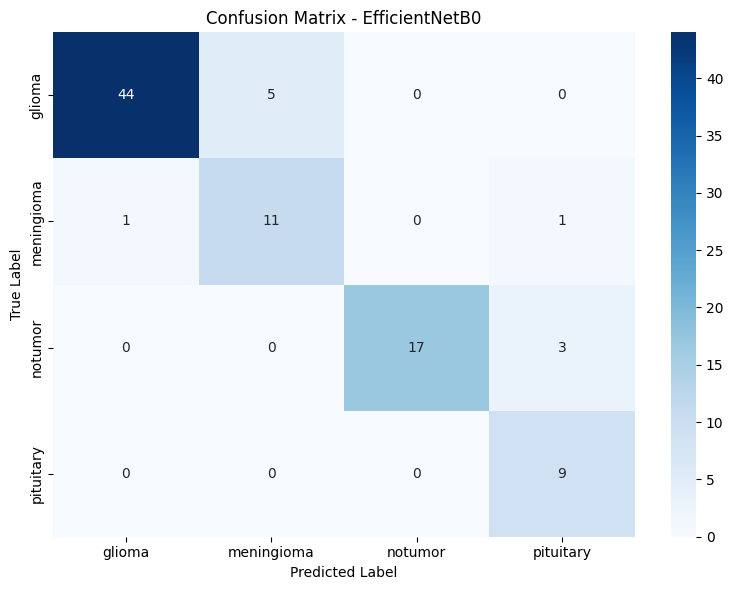

In [ ]:
results_b0 = evaluate_model(
    model=effnetb0,
    X_test=X_test,
    y_test=y_test,
    model_name="EfficientNetB0",
    class_names=CLASS_NAMES,
    no_tumor_label="notumor",
    batch_size=32
)

In [ ]:
# Save model to drive:
effnetb0.save("/content/drive/MyDrive/Brain_Tumor_Classification_Project/effnetb0_model.keras")

- Thus, ***EfficientNetB0*** achieved **accuracy = 0.89**, **Inference Time = 110.8993 ms/image** on the test set and had an **FNR = 0.0000**.

# 3. Model EfficientNetB2:

## 3.1. Load and build model:


In [ ]:
from tensorflow.keras.applications import EfficientNetB2

def build_effnetb2(input_shape=INPUT_SHAPE, num_classes=4):
    inputs = layers.Input(shape=input_shape)

    backbone = EfficientNetB2(
        weights='imagenet',
        include_top=False,
        input_tensor=inputs
    )

    backbone.trainable = False

    outputs = build_classifier_head(
        backbone.output,
        num_classes=num_classes
    )

    return Model(inputs, outputs, name="EfficientNetB2")

In [ ]:
effnetb2 = build_effnetb2()
effnetb2.summary()

Model: "EfficientNetB2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_6         │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_3     │ (None, 224, 224,  │          7 │ rescaling_6[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_7         │ (None, 224, 224,  │          0 │ normalization_3[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_7[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 8,131,325 (31.02 MB)

 Trainable params: 362,244 (1.38 MB)

 Non-trainable params: 7,769,081 (29.64 MB)

## 3.2. Fine-tunning model:

In [ ]:
effnetb2.compile(loss='categorical_crossentropy',optimizer = 'Adam', metrics= ['accuracy'])

In [ ]:
tensorboard_b2 = TensorBoard(
    log_dir='log_b2',
)

checkpoint_b2 = ModelCheckpoint(
    "effnetb2_best.h5",
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

reduce_lr_b2 = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_delta=1e-4,
    min_lr=1e-7,
    verbose=1
)

In [ ]:
history_b2 = effnetb2.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, verbose=1, batch_size=32,
                   callbacks=[tensorboard_b2, checkpoint_b2, reduce_lr_b2])
print("EfficientNetB2 model training completed.")

Epoch 1/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.7232 - loss: 0.7779
Epoch 1: val_loss improved from None to 0.34216, saving model to effnetb2_best.h5



Epoch 1: finished saving model to effnetb2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 81s 168ms/step - accuracy: 0.7834 - loss: 0.5915 - val_accuracy: 0.8740 - val_loss: 0.3422 - learning_rate: 0.0010
Epoch 2/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8341 - loss: 0.4280
Epoch 2: val_loss improved from 0.34216 to 0.27854, saving model to effnetb2_best.h5



Epoch 2: finished saving model to effnetb2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - accuracy: 0.8397 - loss: 0.4213 - val_accuracy: 0.8960 - val_loss: 0.2785 - learning_rate: 0.0010
Epoch 3/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8604 - loss: 0.3730
Epoch 3: val_loss improved from 0.27854 to 0.24901, saving model to effnetb2_best.h5



Epoch 3: finished saving model to effnetb2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - accuracy: 0.8570 - loss: 0.3724 - val_accuracy: 0.9030 - val_loss: 0.2490 - learning_rate: 0.0010
Epoch 4/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8835 - loss: 0.3224
Epoch 4: val_loss improved from 0.24901 to 0.19803, saving model to effnetb2_best.h5



Epoch 4: finished saving model to effnetb2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 18s 60ms/step - accuracy: 0.8818 - loss: 0.3217 - val_accuracy: 0.9333 - val_loss: 0.1980 - learning_rate: 0.0010
Epoch 5/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8807 - loss: 0.3084
Epoch 5: val_loss improved from 0.19803 to 0.19495, saving model to effnetb2_best.h5


...


Epoch 24: finished saving model to effnetb2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 20s 65ms/step - accuracy: 0.9390 - loss: 0.1706 - val_accuracy: 0.9697 - val_loss: 0.1011 - learning_rate: 2.0000e-04
Epoch 25/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9365 - loss: 0.1632
Epoch 25: val_loss improved from 0.10111 to 0.09623, saving model to effnetb2_best.h5



Epoch 25: finished saving model to effnetb2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 20s 65ms/step - accuracy: 0.9380 - loss: 0.1628 - val_accuracy: 0.9710 - val_loss: 0.0962 - learning_rate: 2.0000e-04
Epoch 26/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9422 - loss: 0.1548
Epoch 26: val_loss did not improve from 0.09623
302/302 ━━━━━━━━━━━━━━━━━━━━ 19s 62ms/step - accuracy: 0.9437 - loss: 0.1508 - val_accuracy: 0.9702 - val_loss: 0.0966 - learning_rate: 2.0000e-04
Epoch 27/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9421 - loss: 0.1541
Epoch 27: val_loss improved from 0.09623 to 0.09313, saving model to effnetb2_best.h5



Epoch 27: finished saving model to effnetb2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 21s 65ms/step - accuracy: 0.9449 - loss: 0.1509 - val_accuracy: 0.9722 - val_loss: 0.0931 - learning_rate: 2.0000e-04
Epoch 28/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9402 - loss: 0.1564
Epoch 28: val_loss improved from 0.09313 to 0.09120, saving model to effnetb2_best.h5



Epoch 28: finished saving model to effnetb2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 20s 65ms/step - accuracy: 0.9420 - loss: 0.1525 - val_accuracy: 0.9702 - val_loss: 0.0912 - learning_rate: 2.0000e-04
Epoch 29/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9383 - loss: 0.1571
Epoch 29: val_loss improved from 0.09120 to 0.08618, saving model to effnetb2_best.h5



Epoch 29: finished saving model to effnetb2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 19s 64ms/step - accuracy: 0.9420 - loss: 0.1502 - val_accuracy: 0.9739 - val_loss: 0.0862 - learning_rate: 2.0000e-04
Epoch 30/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9461 - loss: 0.1461
Epoch 30: val_loss did not improve from 0.08618
302/302 ━━━━━━━━━━━━━━━━━━━━ 19s 63ms/step - accuracy: 0.9472 - loss: 0.1460 - val_accuracy: 0.9714 - val_loss: 0.0872 - learning_rate: 2.0000e-04
EfficientNetB2 model training completed.


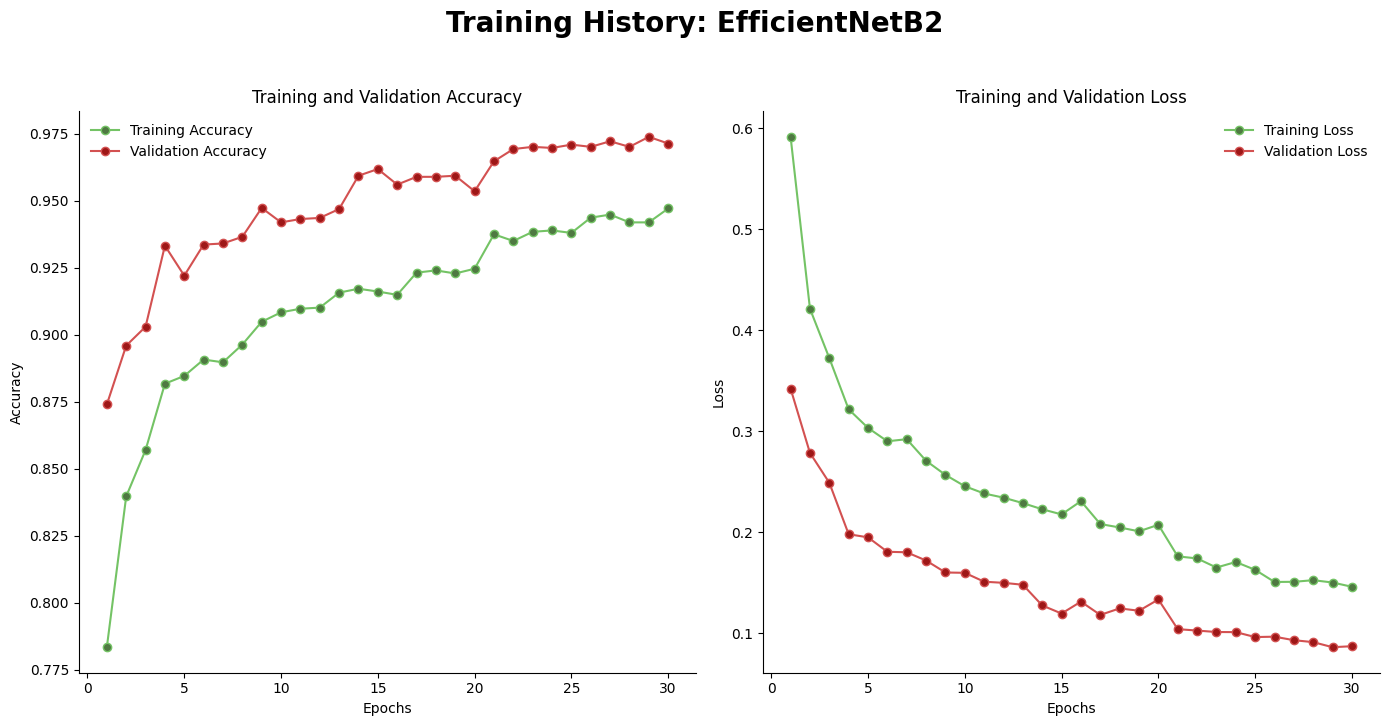

In [ ]:
# Print out the training process:
plot_training_history(history_b2, "EfficientNetB2")

## 3.3. Evaluate the model on the test set:

MODEL EVALUATION: EfficientNetB2
Test samples                 : 91
Batch size                   : 32
Total inference time         : 8.1148 seconds
Average inference time       : 89.1733 ms/image
Throughput                   : 11.21 images/second
----------------------------------------------------------------------
Accuracy                     : 0.9011
Macro Precision              : 0.8781
Macro Recall                 : 0.8828
Macro F1-score               : 0.8791
Weighted Precision           : 0.9031
Weighted Recall              : 0.9011
Weighted F1-score            : 0.9012
----------------------------------------------------------------------
TUMOR-TO-NO-TUMOR FALSE NEGATIVE RATE
Actual tumor images          : 71
Tumor predicted as notumor     : 0
Tumor FNR                    : 0.0000 (0.00%)
----------------------------------------------------------------------
CLASSIFICATION REPORT
              precision  recall  f1-score  support
glioma           0.9200  0.9388    0.9293  49.000

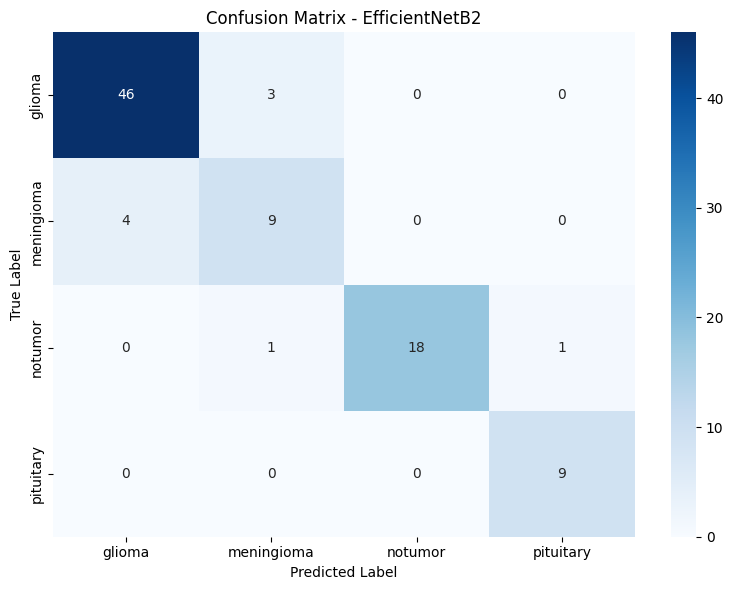

In [ ]:
results_b2 = evaluate_model(
    model=effnetb2,
    X_test=X_test,
    y_test=y_test,
    model_name="EfficientNetB2",
    class_names=CLASS_NAMES,
    no_tumor_label="notumor",
    batch_size=32
)

In [ ]:
# Save model to drive:
effnetb2.save("/content/drive/MyDrive/Brain_Tumor_Classification_Project/EFFNETB2.keras")
print("Model saved successfully.")

Model saved successfully.


Thus, the model ***EfficientNetB2*** achieved **accuracy = 0.90**, **inference time = 89.1733 ms/image**, and **FNR = 0.0000**.

# 4. Model EfficientNetB3:

## 4.1. Load and bulid model EfficientNetB3:

In [ ]:
from tensorflow.keras.applications import EfficientNetB3

def build_effnetb3(input_shape=INPUT_SHAPE, num_classes=4):
    inputs = layers.Input(shape=input_shape)

    backbone = EfficientNetB3(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    backbone.trainable = False

    outputs = build_classifier_head(
        backbone.output,
        num_classes=num_classes
    )

    return Model(inputs, outputs, name="EfficientNetB3")

In [ ]:
effnetb3 = build_effnetb3()
effnetb3.summary()

Model: "EfficientNetB3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_8         │ (None, 224, 224,  │          0 │ input_layer_4[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_4     │ (None, 224, 224,  │          7 │ rescaling_8[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_9         │ (None, 224, 224,  │          0 │ normalization_4[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_9[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │      1,080 │ stem_conv_pad[0]… │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        160 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        360 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        160 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 40)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 40)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 10)  │        410 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 40)  │        440 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 40)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        960 │ block1a_se_excit

 Total params: 11,179,059 (42.64 MB)

 Trainable params: 395,012 (1.51 MB)

 Non-trainable params: 10,784,047 (41.14 MB)

In [ ]:
# Compile model:
effnetb3.compile(loss='categorical_crossentropy',optimizer = 'Adam', metrics= ['accuracy'])

## 4.2. Fine-tunning model:

In [ ]:
tensorboard_b3 = TensorBoard(
    log_dir='log_b3',
)

checkpoint_b3 = ModelCheckpoint(
    "effnetb3_best.h5",
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

reduce_lr_b3 = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_delta=1e-4,
    min_lr=1e-7,
    verbose=1
)

In [ ]:
history_b3 = effnetb3.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, verbose=1, batch_size=32,
                   callbacks=[tensorboard_b3, checkpoint_b3, reduce_lr_b3])
print("EfficientNetB3 model training completed.")

Epoch 1/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.7067 - loss: 0.8239
Epoch 1: val_loss improved from None to 0.33444, saving model to effnetb3_best.h5



Epoch 1: finished saving model to effnetb3_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 89s 185ms/step - accuracy: 0.7725 - loss: 0.6194 - val_accuracy: 0.8761 - val_loss: 0.3344 - learning_rate: 0.0010
Epoch 2/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.8351 - loss: 0.4291
Epoch 2: val_loss improved from 0.33444 to 0.25451, saving model to effnetb3_best.h5



Epoch 2: finished saving model to effnetb3_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 24s 80ms/step - accuracy: 0.8450 - loss: 0.4077 - val_accuracy: 0.8981 - val_loss: 0.2545 - learning_rate: 0.0010
Epoch 3/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.8623 - loss: 0.3682
Epoch 3: val_loss improved from 0.25451 to 0.23447, saving model to effnetb3_best.h5



Epoch 3: finished saving model to effnetb3_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 24s 81ms/step - accuracy: 0.8641 - loss: 0.3588 - val_accuracy: 0.9084 - val_loss: 0.2345 - learning_rate: 0.0010
Epoch 4/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.8769 - loss: 0.3267
Epoch 4: val_loss improved from 0.23447 to 0.20953, saving model to effnetb3_best.h5



Epoch 4: finished saving model to effnetb3_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 25s 82ms/step - accuracy: 0.8758 - loss: 0.3265 - val_accuracy: 0.9192 - val_loss: 0.2095 - learning_rate: 0.0010
Epoch 5/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.8834 - loss: 0.3010
Epoch 5: val_loss improved from 0.20953 to 0.19891, saving model to effnetb3_best.h5


...


Epoch 26: finished saving model to effnetb3_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 26s 87ms/step - accuracy: 0.9455 - loss: 0.1516 - val_accuracy: 0.9677 - val_loss: 0.0899 - learning_rate: 2.0000e-04
Epoch 27/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9459 - loss: 0.1451
Epoch 27: val_loss improved from 0.08991 to 0.08889, saving model to effnetb3_best.h5



Epoch 27: finished saving model to effnetb3_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 26s 87ms/step - accuracy: 0.9467 - loss: 0.1416 - val_accuracy: 0.9677 - val_loss: 0.0889 - learning_rate: 2.0000e-04
Epoch 28/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9489 - loss: 0.1359
Epoch 28: val_loss improved from 0.08889 to 0.08735, saving model to effnetb3_best.h5



Epoch 28: finished saving model to effnetb3_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 26s 87ms/step - accuracy: 0.9481 - loss: 0.1406 - val_accuracy: 0.9685 - val_loss: 0.0873 - learning_rate: 2.0000e-04
Epoch 29/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9518 - loss: 0.1320
Epoch 29: val_loss improved from 0.08735 to 0.08599, saving model to effnetb3_best.h5



Epoch 29: finished saving model to effnetb3_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 26s 87ms/step - accuracy: 0.9472 - loss: 0.1423 - val_accuracy: 0.9714 - val_loss: 0.0860 - learning_rate: 2.0000e-04
Epoch 30/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9469 - loss: 0.1390
Epoch 30: val_loss improved from 0.08599 to 0.08206, saving model to effnetb3_best.h5



Epoch 30: finished saving model to effnetb3_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 26s 86ms/step - accuracy: 0.9498 - loss: 0.1327 - val_accuracy: 0.9706 - val_loss: 0.0821 - learning_rate: 2.0000e-04
EfficientNetB3 model training completed.


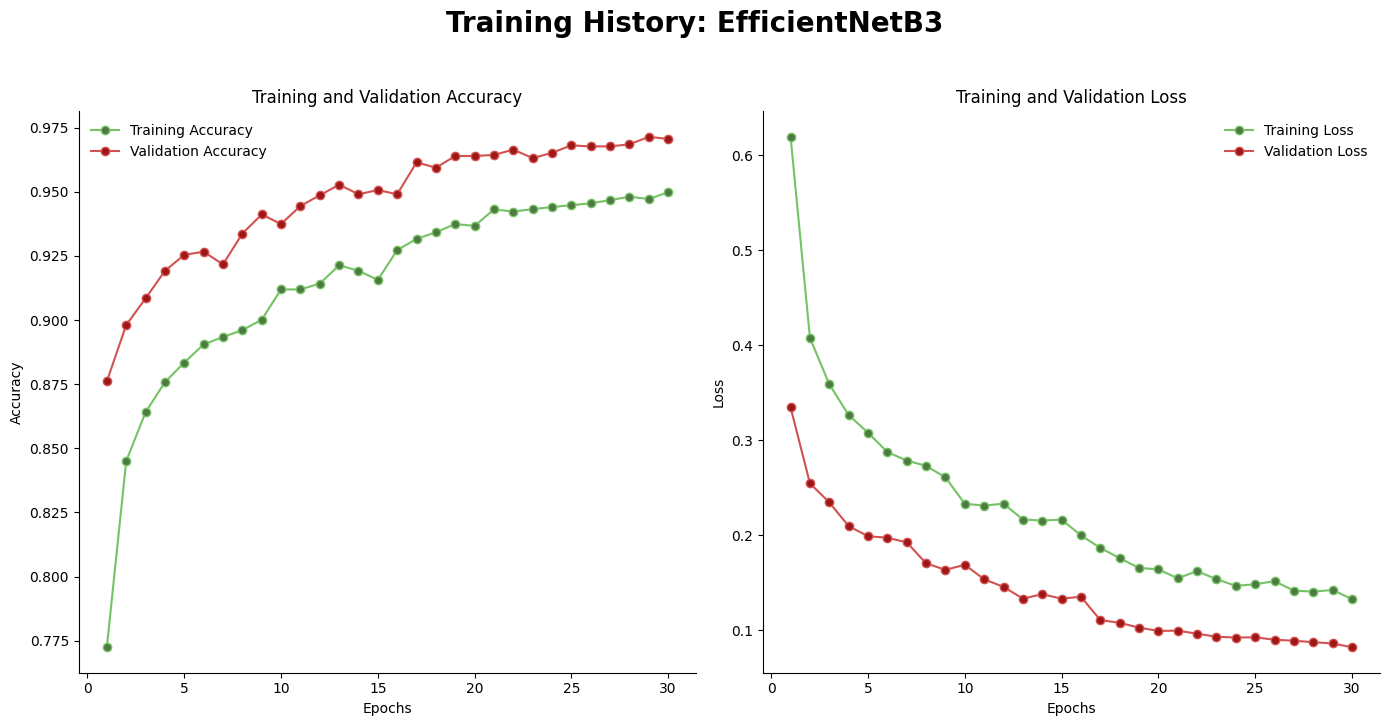

In [ ]:
# Print out the training process:
plot_training_history(history_b3, "EfficientNetB3")

## 4.3. Evaluate the model on the test set:

MODEL EVALUATION: EfficientNetB3
Test samples                 : 91
Batch size                   : 32
Total inference time         : 8.7285 seconds
Average inference time       : 95.9178 ms/image
Throughput                   : 10.43 images/second
----------------------------------------------------------------------
Accuracy                     : 0.9011
Macro Precision              : 0.8594
Macro Recall                 : 0.8594
Macro F1-score               : 0.8545
Weighted Precision           : 0.9084
Weighted Recall              : 0.9011
Weighted F1-score            : 0.9013
----------------------------------------------------------------------
TUMOR-TO-NO-TUMOR FALSE NEGATIVE RATE
Actual tumor images          : 71
Tumor predicted as notumor     : 0
Tumor FNR                    : 0.0000 (0.00%)
----------------------------------------------------------------------
CLASSIFICATION REPORT
              precision  recall  f1-score  support
glioma           0.9412  0.9796    0.9600  49.000

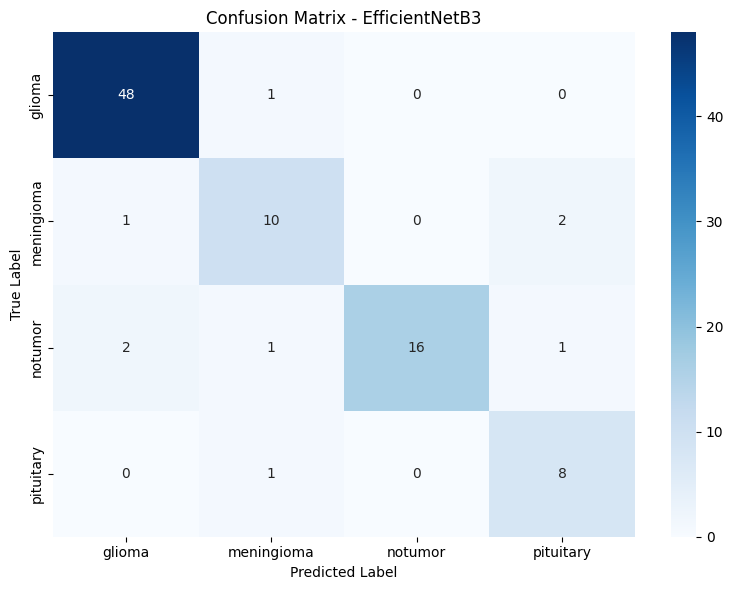

In [ ]:
results_b3 = evaluate_model(
    model=effnetb3,
    X_test=X_test,
    y_test=y_test,
    model_name="EfficientNetB3",
    class_names=CLASS_NAMES,
    no_tumor_label="notumor",
    batch_size=32
)

In [ ]:
# Save model to drive:
effnetb3.save("/content/drive/MyDrive/Brain_Tumor_Classification_Project/effnetb3_model.keras")
print("Model saved successfully.")

Model saved successfully.


Thus, the model ***EfficientNetB3*** achieved **Accuracy = 0.90**, **Time Inference = 95.9178 ms/image**, and **FNR = 0.0000**!

# 5. EfficientNetV2-S model:

## 5.1. Load and build model:

In [ ]:
# Load and bulid model EfficientNetV2S:
from tensorflow.keras.applications import EfficientNetV2S

def build_effnetv2s(input_shape=INPUT_SHAPE, num_classes=4):
    inputs = layers.Input(shape=input_shape)

    backbone = EfficientNetV2S(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    backbone.trainable = False

    outputs = build_classifier_head(
        backbone.output,
        num_classes=num_classes
    )

    return Model(inputs, outputs, name="EfficientNetV2S")

In [ ]:
effnetv2s = build_effnetv2s()
effnetv2s.summary()

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "EfficientNetV2S"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        648 │ rescaling[0][0]   │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │         96 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      5,184 │ stem_activation[… │
│ (Conv2D)            │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, 112, 112,  │         96 │ block1a_project_… │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, 112, 112,  │          0 │ block1a_project_… │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_add (Add)   │ (None, 112, 112,  │          0 │ block1a_project_… │
│                     │ 24)               │            │ stem_activation[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_co… │ (None, 112, 112,  │      5,184 │ block1a_add[0][0] │
│ (Conv2D)            │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_bn  │ (None, 112, 112,  │         96 │ block1b_project_… │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_ac… │ (None, 112, 112,  │          0 │ block1b_project_… │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_drop        │ (None, 112, 112,  │          0 │ block1b_project_… │
│ (Dropout)           │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_add (Add)   │ (None, 112, 112,  │          0 │ block1b_drop[0][… │
│                     │ 24)               │            │ block1a_add[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, 56, 56,    │     20,736 │ block1b_add[0][0] │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, 56, 56,    │        384 │ block2a_expand_c… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, 56, 56,    │          0 │ block2a_expand_b

 Total params: 20,661,348 (78.82 MB)

 Trainable params: 329,476 (1.26 MB)

 Non-trainable params: 20,331,872 (77.56 MB)

In [ ]:
# Compile model:
effnetv2s.compile(loss='categorical_crossentropy',optimizer = 'Adam', metrics= ['accuracy'])

## 5.2. Fine-tunning Model:

In [ ]:
tensorboard_v2s = TensorBoard(
    log_dir='log_v2s',
)

checkpoint_v2s = ModelCheckpoint(
    "effnetv2s_best.h5",
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

reduce_lr_v2s = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_delta=1e-4,
    min_lr=1e-7,
    verbose=1
)

In [ ]:
# Fine-tunning model:
history_v2s = effnetv2s.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, verbose=1, batch_size=32,
                   callbacks=[tensorboard_v2s, checkpoint_v2s, reduce_lr_v2s])
print("EfficientNetV2S model training completed.")

Epoch 1/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.7079 - loss: 0.8445
Epoch 1: val_loss improved from None to 0.39708, saving model to effnetv2s_best.h5



Epoch 1: finished saving model to effnetv2s_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 124s 254ms/step - accuracy: 0.7623 - loss: 0.6559 - val_accuracy: 0.8326 - val_loss: 0.3971 - learning_rate: 0.0010
Epoch 2/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.8090 - loss: 0.4944
Epoch 2: val_loss improved from 0.39708 to 0.31335, saving model to effnetv2s_best.h5



Epoch 2: finished saving model to effnetv2s_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 33s 108ms/step - accuracy: 0.8174 - loss: 0.4706 - val_accuracy: 0.8798 - val_loss: 0.3133 - learning_rate: 0.0010
Epoch 3/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8432 - loss: 0.4002
Epoch 3: val_loss improved from 0.31335 to 0.26352, saving model to effnetv2s_best.h5



Epoch 3: finished saving model to effnetv2s_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 34s 111ms/step - accuracy: 0.8383 - loss: 0.4092 - val_accuracy: 0.9018 - val_loss: 0.2635 - learning_rate: 0.0010
Epoch 4/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.8538 - loss: 0.3792
Epoch 4: val_loss improved from 0.26352 to 0.24579, saving model to effnetv2s_best.h5



Epoch 4: finished saving model to effnetv2s_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 34s 113ms/step - accuracy: 0.8540 - loss: 0.3822 - val_accuracy: 0.9068 - val_loss: 0.2458 - learning_rate: 0.0010
Epoch 5/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.8595 - loss: 0.3616
Epoch 5: val_loss did not improve from 0.24579
302/302 ━━━━━━━━━━━━━━━━━━━━ 34s 112ms/step - accuracy: 0.8624 - loss: 0.3581 - val_accuracy: 0.9026 - val_loss: 0.2486 - learning_rate: 0.0010
Epoch 6/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.8700 - loss: 0.3455
Epoch 6: val_loss improved from 0.24579 to 0.22081, saving model to effnetv2s_best.h5


...


Epoch 21: finished saving model to effnetv2s_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 37s 122ms/step - accuracy: 0.9143 - loss: 0.2330 - val_accuracy: 0.9540 - val_loss: 0.1306 - learning_rate: 0.0010
Epoch 22/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9164 - loss: 0.2306
Epoch 22: val_loss did not improve from 0.13061
302/302 ━━━━━━━━━━━━━━━━━━━━ 36s 119ms/step - accuracy: 0.9175 - loss: 0.2273 - val_accuracy: 0.9557 - val_loss: 0.1339 - learning_rate: 0.0010
Epoch 23/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9162 - loss: 0.2309
Epoch 23: val_loss improved from 0.13061 to 0.13004, saving model to effnetv2s_best.h5



Epoch 23: finished saving model to effnetv2s_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 37s 122ms/step - accuracy: 0.9189 - loss: 0.2268 - val_accuracy: 0.9519 - val_loss: 0.1300 - learning_rate: 0.0010
Epoch 24/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9186 - loss: 0.2100
Epoch 24: val_loss did not improve from 0.13004
302/302 ━━━━━━━━━━━━━━━━━━━━ 36s 119ms/step - accuracy: 0.9203 - loss: 0.2137 - val_accuracy: 0.9486 - val_loss: 0.1371 - learning_rate: 0.0010
Epoch 25/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9157 - loss: 0.2240
Epoch 25: val_loss improved from 0.13004 to 0.12118, saving model to effnetv2s_best.h5



Epoch 25: finished saving model to effnetv2s_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 37s 122ms/step - accuracy: 0.9162 - loss: 0.2251 - val_accuracy: 0.9586 - val_loss: 0.1212 - learning_rate: 0.0010
Epoch 26/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9253 - loss: 0.2063
Epoch 26: val_loss did not improve from 0.12118
302/302 ━━━━━━━━━━━━━━━━━━━━ 36s 119ms/step - accuracy: 0.9199 - loss: 0.2152 - val_accuracy: 0.9528 - val_loss: 0.1262 - learning_rate: 0.0010
Epoch 27/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9191 - loss: 0.2184
Epoch 27: val_loss did not improve from 0.12118
302/302 ━━━━━━━━━━━━━━━━━━━━ 36s 119ms/step - accuracy: 0.9180 - loss: 0.2178 - val_accuracy: 0.9610 - val_loss: 0.1223 - learning_rate: 0.0010
Epoch 28/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9186 - loss: 0.2107
Epoch 28: val_loss improved from 0.12118 to 0.12085, saving model to effnetv2s_best.h5



Epoch 28: finished saving model to effnetv2s_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 37s 122ms/step - accuracy: 0.9205 - loss: 0.2129 - val_accuracy: 0.9573 - val_loss: 0.1209 - learning_rate: 0.0010
Epoch 29/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9233 - loss: 0.2135
Epoch 29: val_loss improved from 0.12085 to 0.11083, saving model to effnetv2s_best.h5



Epoch 29: finished saving model to effnetv2s_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 37s 121ms/step - accuracy: 0.9228 - loss: 0.2079 - val_accuracy: 0.9627 - val_loss: 0.1108 - learning_rate: 0.0010
Epoch 30/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9180 - loss: 0.2169
Epoch 30: val_loss did not improve from 0.11083
302/302 ━━━━━━━━━━━━━━━━━━━━ 36s 118ms/step - accuracy: 0.9184 - loss: 0.2153 - val_accuracy: 0.9598 - val_loss: 0.1159 - learning_rate: 0.0010
EfficientNetV2S model training completed.


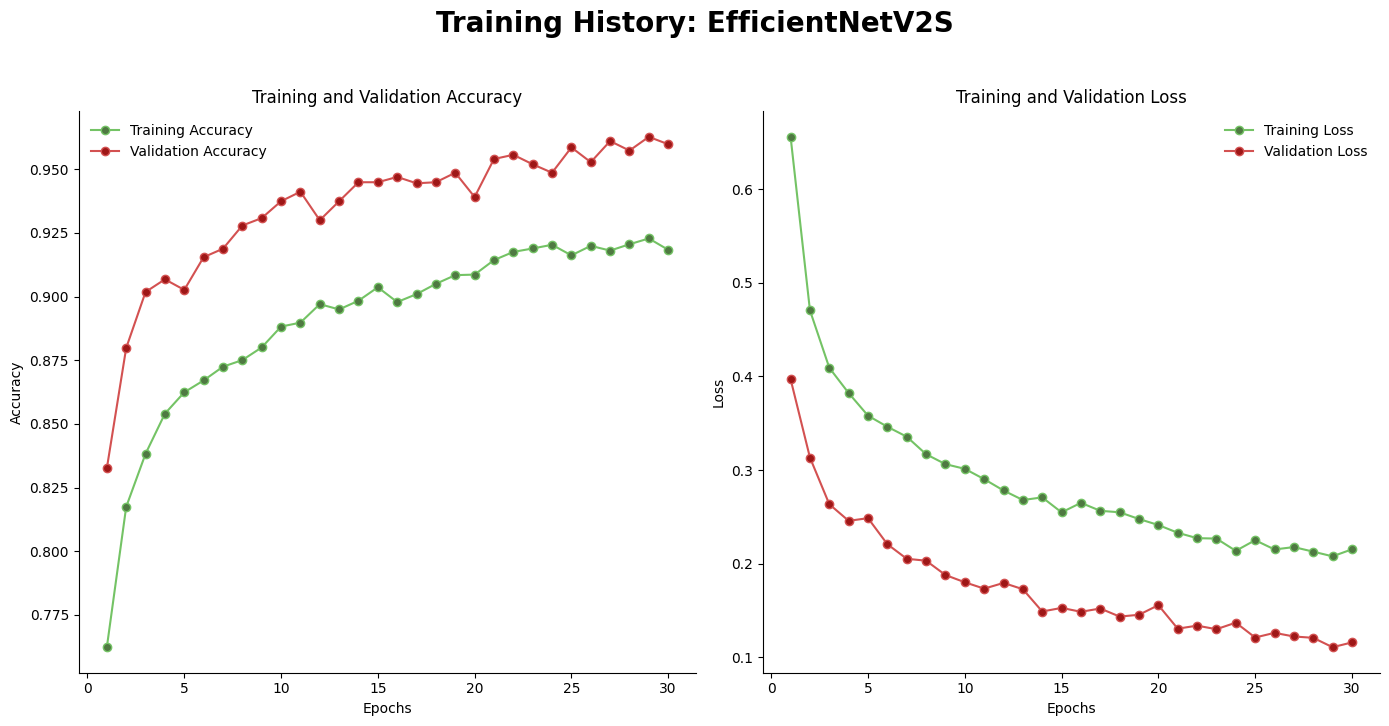

In [ ]:
# Print out training process:
plot_training_history(history_v2s, "EfficientNetV2S")

## 5.3. Evaluate model on test set:

MODEL EVALUATION: EfficientNetV2-S
Test samples                 : 91
Batch size                   : 32
Total inference time         : 11.5284 seconds
Average inference time       : 126.6859 ms/image
Throughput                   : 7.89 images/second
----------------------------------------------------------------------
Accuracy                     : 0.8791
Macro Precision              : 0.8316
Macro Recall                 : 0.8928
Macro F1-score               : 0.8440
Weighted Precision           : 0.9107
Weighted Recall              : 0.8791
Weighted F1-score            : 0.8842
----------------------------------------------------------------------
TUMOR-TO-NO-TUMOR FALSE NEGATIVE RATE
Actual tumor images          : 71
Tumor predicted as notumor     : 0
Tumor FNR                    : 0.0000 (0.00%)
----------------------------------------------------------------------
CLASSIFICATION REPORT
              precision  recall  f1-score  support
glioma           0.9778  0.8980    0.9362  49.

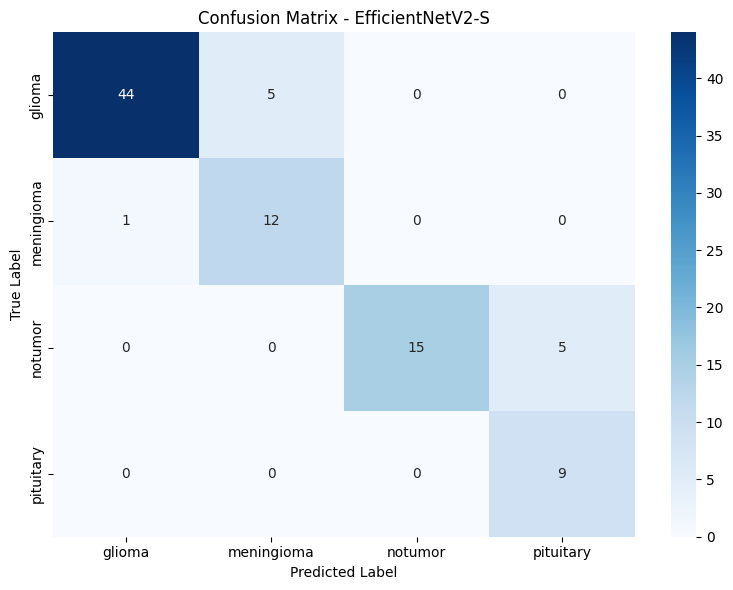

In [ ]:
import time
results_v2s = evaluate_model(
    model=effnetv2s,
    X_test=X_test,
    y_test=y_test,
    model_name="EfficientNetV2-S",
    class_names=CLASS_NAMES,
    no_tumor_label="notumor",
    batch_size=32
)

In [ ]:
# Save model to drive:
effnetv2s.save("/content/drive/MyDrive/Brain_Tumor_Classification_Project/effnetv2s_model.keras")
print("Model saved successfully.")

Model saved successfully.


Thus, the model ***EfficientNetV2S*** achieved **Accuracy = 0.87**, **Time Inference = 126.6859 ms/image**, and **FNR = 0.0000**!

# 6. Model EfficientNetB0 + CBAM:

## 6.1. Load and buil model:

In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

# Define CBAM:
def cbam_block(inputs, reduction=8, name=None):
    channel = inputs.shape[-1]

    # Channel Attention Module:
    # Layer averages each channel and takes the maximum value for each channel:
    avg_pool = layers.GlobalAveragePooling2D()(inputs)
    max_pool = layers.GlobalMaxPooling2D()(inputs)

    # MLP shares weights:
    shared_mlp = models.Sequential([
        layers.Dense(channel // reduction, activation='relu'),
        layers.Dense(channel)
    ])

    avg_out = shared_mlp(avg_pool)
    max_out = shared_mlp(max_pool)

    # Combine + Sigmoid to create channel weight maps:
    channel_attention = layers.Activation('sigmoid')(avg_out + max_out)
    channel_attention = layers.Reshape((1, 1, channel))(channel_attention)

    # Multiply by the feature map:
    x = layers.Multiply()([inputs, channel_attention])

    # Spatial Attention Module:
    # Bước 1: Pooling acrording to channel:
    avg_pool = layers.Lambda(
        lambda x: tf.reduce_mean(x, axis=-1, keepdims=True))(x)
    max_pool = layers.Lambda(
        lambda x: tf.reduce_max(x, axis=-1, keepdims=True))(x)
    # Concat two feature:
    concat = layers.Concatenate(axis=-1)([avg_pool, max_pool])
    # Convolution 7×7 + sigmoid to learn area feature:
    spatial_attention = layers.Conv2D(
        filters=1,
        kernel_size=7,
        padding='same',
        activation='sigmoid'
    )(concat)
    # Multiply by the feature map:
    x = layers.Multiply()([x, spatial_attention])

    return x


In [ ]:
def build_effnetb0_cbam(
    input_shape=INPUT_SHAPE,
    num_classes=4,
):
    inputs = layers.Input(shape=input_shape)

    # Backbone
    backbone = EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_tensor=inputs
    )
    backbone.trainable = False

    x = backbone.output

    # Add CBAM:
    x = cbam_block(x)

    # Add head:
    outputs = build_classifier_head(
        x,
        num_classes=num_classes
    )

    model = Model(inputs, outputs, name='EfficientNetB0_CBAM')

    return model

In [ ]:
effnetb0_cbam = build_effnetb0_cbam()
effnetb0_cbam.summary()

Model: "EfficientNetB0_CBAM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_3         │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_1     │ (None, 224, 224,  │          7 │ rescaling_3[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_4         │ (None, 224, 224,  │          0 │ normalization_1[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_4[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,790,698 (18.28 MB)

 Trainable params: 740,615 (2.83 MB)

 Non-trainable params: 4,050,083 (15.45 MB)

In [ ]:
effnetb0_cbam.compile(loss='categorical_crossentropy',optimizer = 'Adam', metrics= ['accuracy'])

## 6.2. Fine-tune Model:

In [ ]:
tensorboard_b0_cbam = TensorBoard(
    log_dir='log_b0_cbam',
)

checkpoint_b0_cbam = ModelCheckpoint(
    "effnetb0_cbam_best.h5",
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

reduce_lr_b0_cbam = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_delta=1e-4,
    min_lr=1e-7,
    verbose=1
)

earrly_stopping_b0_cbam = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    verbose=1,
    restore_best_weights=True
)

In [ ]:
# Fine-tunning head and CBAM block:
history_b0_cbam = effnetb0_cbam.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, verbose=1, batch_size=32,
                   callbacks=[tensorboard_b0_cbam, checkpoint_b0_cbam, reduce_lr_b0_cbam, earrly_stopping_b0_cbam])
print("EfficientNetficientNetB0 + CBAM model training completed.")

Epoch 1/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.7108 - loss: 0.7264
Epoch 1: val_loss improved from None to 0.80864, saving model to effnetb0_cbam_best.h5



Epoch 1: finished saving model to effnetb0_cbam_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 75s 147ms/step - accuracy: 0.7759 - loss: 0.5767 - val_accuracy: 0.7186 - val_loss: 0.8086 - learning_rate: 0.0010
Epoch 2/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8516 - loss: 0.3948
Epoch 2: val_loss improved from 0.80864 to 0.30350, saving model to effnetb0_cbam_best.h5



Epoch 2: finished saving model to effnetb0_cbam_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.8663 - loss: 0.3624 - val_accuracy: 0.8848 - val_loss: 0.3035 - learning_rate: 0.0010
Epoch 3/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8950 - loss: 0.2902
Epoch 3: val_loss improved from 0.30350 to 0.23135, saving model to effnetb0_cbam_best.h5



Epoch 3: finished saving model to effnetb0_cbam_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.9014 - loss: 0.2699 - val_accuracy: 0.9084 - val_loss: 0.2313 - learning_rate: 0.0010
Epoch 4/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9177 - loss: 0.2142
Epoch 4: val_loss did not improve from 0.23135
302/302 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.9207 - loss: 0.2128 - val_accuracy: 0.8583 - val_loss: 0.3592 - learning_rate: 0.0010
Epoch 5/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9312 - loss: 0.1961
Epoch 5: val_loss improved from 0.23135 to 0.18976, saving model to effnetb0_cbam_best.h5



Epoch 5: finished saving model to effnetb0_cbam_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.9346 - loss: 0.1913 - val_accuracy: 0.9271 - val_loss: 0.1898 - learning_rate: 0.0010
Epoch 6/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9459 - loss: 0.1556
Epoch 6: val_loss improved from 0.18976 to 0.11542, saving model to effnetb0_cbam_best.h5


...


Epoch 12: finished saving model to effnetb0_cbam_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9791 - loss: 0.0610 - val_accuracy: 0.9743 - val_loss: 0.0757 - learning_rate: 2.0000e-04
Epoch 13/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9819 - loss: 0.0548
Epoch 13: val_loss improved from 0.07567 to 0.07236, saving model to effnetb0_cbam_best.h5



Epoch 13: finished saving model to effnetb0_cbam_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9806 - loss: 0.0559 - val_accuracy: 0.9764 - val_loss: 0.0724 - learning_rate: 2.0000e-04
Epoch 14/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9843 - loss: 0.0497
Epoch 14: val_loss did not improve from 0.07236
302/302 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.9830 - loss: 0.0507 - val_accuracy: 0.9743 - val_loss: 0.0730 - learning_rate: 2.0000e-04
Epoch 15/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9828 - loss: 0.0507
Epoch 15: val_loss improved from 0.07236 to 0.06884, saving model to effnetb0_cbam_best.h5



Epoch 15: finished saving model to effnetb0_cbam_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9847 - loss: 0.0470 - val_accuracy: 0.9793 - val_loss: 0.0688 - learning_rate: 2.0000e-04
Epoch 16/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9853 - loss: 0.0418
Epoch 16: val_loss did not improve from 0.06884
302/302 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.9832 - loss: 0.0462 - val_accuracy: 0.9739 - val_loss: 0.0742 - learning_rate: 2.0000e-04
Epoch 17/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9877 - loss: 0.0371
Epoch 17: val_loss did not improve from 0.06884
302/302 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.9854 - loss: 0.0411 - val_accuracy: 0.9747 - val_loss: 0.0813 - learning_rate: 2.0000e-04
Epoch 18/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9862 - loss: 0.0436
Epoch 18: val_loss did not improve from 0.06884

Epoch 18: ReduceLROnPlateau reducing learning rate to 4.0000001899898055e-05.
302/302 ━━━━━━


Epoch 19: finished saving model to effnetb0_cbam_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9894 - loss: 0.0326 - val_accuracy: 0.9768 - val_loss: 0.0683 - learning_rate: 4.0000e-05
Epoch 20/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9902 - loss: 0.0298
Epoch 20: val_loss improved from 0.06831 to 0.06534, saving model to effnetb0_cbam_best.h5



Epoch 20: finished saving model to effnetb0_cbam_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9898 - loss: 0.0313 - val_accuracy: 0.9805 - val_loss: 0.0653 - learning_rate: 4.0000e-05
Epoch 21/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9900 - loss: 0.0287
Epoch 21: val_loss did not improve from 0.06534
302/302 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.9904 - loss: 0.0310 - val_accuracy: 0.9764 - val_loss: 0.0669 - learning_rate: 4.0000e-05
Epoch 22/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9891 - loss: 0.0319
Epoch 22: val_loss did not improve from 0.06534
302/302 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.9897 - loss: 0.0325 - val_accuracy: 0.9776 - val_loss: 0.0674 - learning_rate: 4.0000e-05
Epoch 23/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9913 - loss: 0.0264
Epoch 23: val_loss did not improve from 0.06534

Epoch 23: ReduceLROnPlateau reducing learning rate to 8.000000525498762e-06.
302/302 ━━━━━━━

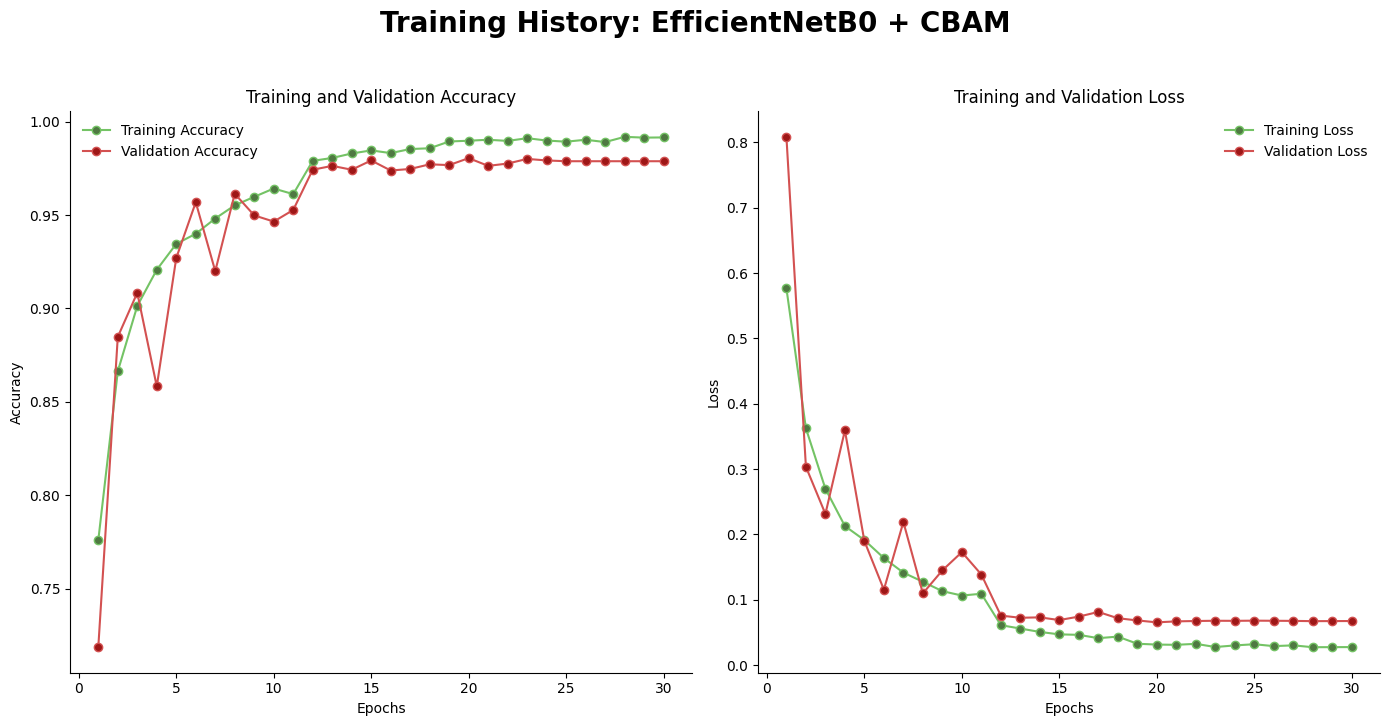

In [ ]:
# Print out training process:
plot_training_history(history_b0_cbam, "EfficientNetB0 + CBAM")


## 6.3. Evaluate model on test set:

MODEL EVALUATION: EfficientNetB0+CBAM
Test samples                 : 91
Batch size                   : 32
Total inference time         : 11.2898 seconds
Average inference time       : 124.0632 ms/image
Throughput                   : 8.06 images/second
----------------------------------------------------------------------
Accuracy                     : 0.9341
Macro Precision              : 0.9056
Macro Recall                 : 0.9546
Macro F1-score               : 0.9227
Weighted Precision           : 0.9504
Weighted Recall              : 0.9341
Weighted F1-score            : 0.9373
----------------------------------------------------------------------
TUMOR-TO-NO-TUMOR FALSE NEGATIVE RATE
Actual tumor images          : 71
Tumor predicted as notumor     : 0
Tumor FNR                    : 0.0000 (0.00%)
----------------------------------------------------------------------
CLASSIFICATION REPORT
              precision  recall  f1-score  support
glioma           1.0000  0.9184    0.9574  

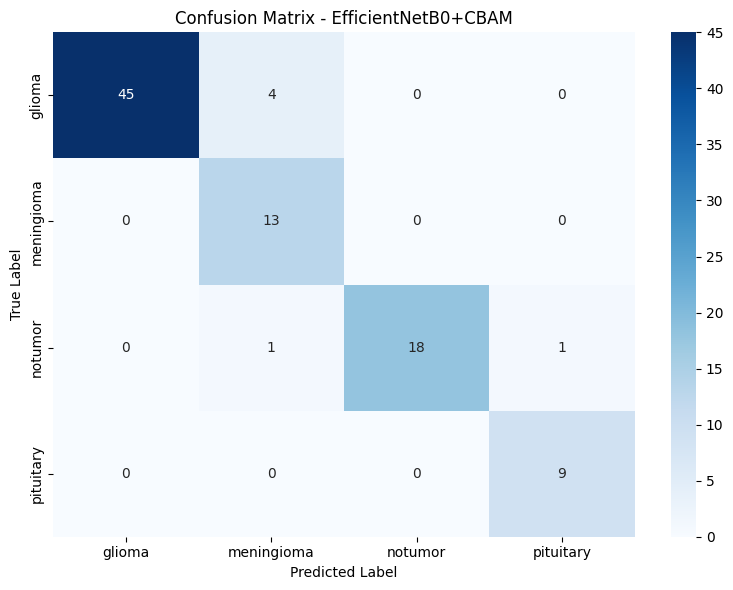

In [ ]:
results_b0_cbam  = evaluate_model(
    model=effnetb0_cbam,
    X_test=X_test,
    y_test=y_test,
    model_name="EfficientNetB0+CBAM",
    class_names=CLASS_NAMES,
    no_tumor_label="notumor",
    batch_size=32
)

In [ ]:
# Save model to drive:
effnetb0_cbam.save("/content/drive/MyDrive/Brain_Tumor_Classification_Project/effnetb0_cbam_model.keras")
print("Model saved successfully.")

Model saved successfully.


Thus, the model ***EfficientNetB0 + CBAM*** achieved **Accuracy = 0.9341**, **Time Inference = 124.0632 ms/image**, and **FNR = 0.0000**!

# 7. Model VGG16

## 7.1. Load and build model:

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model

In [ ]:
# Load model vgg16:
def build_vgg16(input_shape=INPUT_SHAPE, num_classes=4):
    inputs = layers.Input(shape=input_shape)

    vgg16 = VGG16(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    vgg16.trainable = False

    outputs = build_classifier_head(
        vgg16.output,
        num_classes=num_classes
    )

    return Model(inputs, outputs, name="VGG16")

In [ ]:
vgg16 = build_vgg16()
vgg16.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VGG16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             

 Total params: 14,848,068 (56.64 MB)

 Trainable params: 132,868 (519.02 KB)

 Non-trainable params: 14,715,200 (56.13 MB)

In [ ]:
vgg16.compile(loss='categorical_crossentropy',optimizer = 'Adam', metrics= ['accuracy'])

## 7.2. Fine-tuning model:

In [ ]:
tensorboard_vgg16 = TensorBoard(
    log_dir='log_vgg16',
)

checkpoint_vgg16 = ModelCheckpoint(
    "vgg16_best.h5",
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

reduce_lr_vgg16 = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_delta=1e-4,
    min_lr=1e-7,
    verbose=1
)

early_stopping_vgg16 = EarlyStopping(
    monitor='val_loss',
    patience=5,
    verbose=1
)


In [ ]:
# Fine-tuning model:
history_vgg16_head = vgg16.fit(X_train, y_train,
                              validation_data=(X_val, y_val),
                              batch_size=32,
                              epochs=30,
                              verbose=1,
                              callbacks=[tensorboard_vgg16, checkpoint_vgg16, reduce_lr_vgg16, early_stopping_vgg16])

Epoch 1/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.6754 - loss: 0.9062
Epoch 1: val_loss improved from None to 0.38152, saving model to vgg16_best.h5



Epoch 1: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 64s 188ms/step - accuracy: 0.7389 - loss: 0.7207 - val_accuracy: 0.8690 - val_loss: 0.3815 - learning_rate: 0.0010
Epoch 2/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.8022 - loss: 0.5438
Epoch 2: val_loss improved from 0.38152 to 0.35539, saving model to vgg16_best.h5



Epoch 2: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 52s 172ms/step - accuracy: 0.8031 - loss: 0.5345 - val_accuracy: 0.8815 - val_loss: 0.3554 - learning_rate: 0.0010
Epoch 3/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.8182 - loss: 0.4791
Epoch 3: val_loss improved from 0.35539 to 0.32471, saving model to vgg16_best.h5



Epoch 3: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 55s 181ms/step - accuracy: 0.8188 - loss: 0.4774 - val_accuracy: 0.8798 - val_loss: 0.3247 - learning_rate: 0.0010
Epoch 4/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - accuracy: 0.8290 - loss: 0.4486
Epoch 4: val_loss improved from 0.32471 to 0.28623, saving model to vgg16_best.h5



Epoch 4: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 57s 188ms/step - accuracy: 0.8312 - loss: 0.4448 - val_accuracy: 0.9005 - val_loss: 0.2862 - learning_rate: 0.0010
Epoch 5/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - accuracy: 0.8428 - loss: 0.4313
Epoch 5: val_loss improved from 0.28623 to 0.27698, saving model to vgg16_best.h5


...


Epoch 24: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 59s 197ms/step - accuracy: 0.9028 - loss: 0.2577 - val_accuracy: 0.9457 - val_loss: 0.1660 - learning_rate: 2.0000e-04
Epoch 25/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.9077 - loss: 0.2554
Epoch 25: val_loss did not improve from 0.16596
302/302 ━━━━━━━━━━━━━━━━━━━━ 59s 197ms/step - accuracy: 0.9067 - loss: 0.2558 - val_accuracy: 0.9424 - val_loss: 0.1676 - learning_rate: 2.0000e-04
Epoch 26/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.9097 - loss: 0.2455
Epoch 26: val_loss improved from 0.16596 to 0.16128, saving model to vgg16_best.h5



Epoch 26: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 60s 197ms/step - accuracy: 0.9072 - loss: 0.2461 - val_accuracy: 0.9470 - val_loss: 0.1613 - learning_rate: 2.0000e-04
Epoch 27/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.9099 - loss: 0.2442
Epoch 27: val_loss improved from 0.16128 to 0.15457, saving model to vgg16_best.h5



Epoch 27: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 59s 197ms/step - accuracy: 0.9081 - loss: 0.2472 - val_accuracy: 0.9478 - val_loss: 0.1546 - learning_rate: 2.0000e-04
Epoch 28/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.9125 - loss: 0.2363
Epoch 28: val_loss did not improve from 0.15457
302/302 ━━━━━━━━━━━━━━━━━━━━ 59s 195ms/step - accuracy: 0.9091 - loss: 0.2439 - val_accuracy: 0.9457 - val_loss: 0.1568 - learning_rate: 2.0000e-04
Epoch 29/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.9090 - loss: 0.2414
Epoch 29: val_loss improved from 0.15457 to 0.15377, saving model to vgg16_best.h5



Epoch 29: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 60s 197ms/step - accuracy: 0.9137 - loss: 0.2368 - val_accuracy: 0.9482 - val_loss: 0.1538 - learning_rate: 2.0000e-04
Epoch 30/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.9162 - loss: 0.2248
Epoch 30: val_loss improved from 0.15377 to 0.15001, saving model to vgg16_best.h5



Epoch 30: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 59s 196ms/step - accuracy: 0.9093 - loss: 0.2436 - val_accuracy: 0.9486 - val_loss: 0.1500 - learning_rate: 2.0000e-04


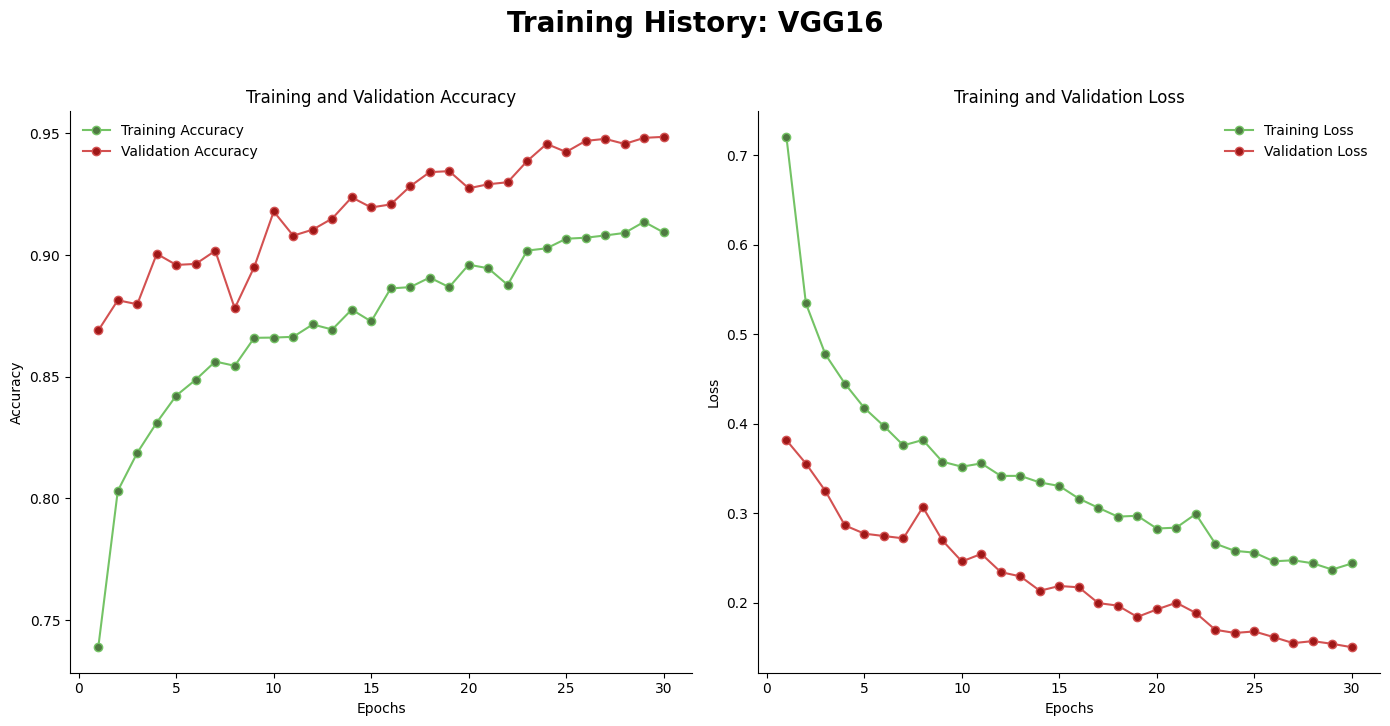

In [ ]:
# Print out training process:
plot_training_history(history_vgg16_head, "VGG16")

In [ ]:
# Unfrezed last block to fine tuning:
for layer in vgg16.layers:
    if "block5" in layer.name:
        layer.trainable = True

In [ ]:
# Re-Compile with smaller learning rate:
vgg16.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
# Fine-tune more with 30 epoch:
history_vgg16 = vgg16.fit(X_train, y_train,
                              batch_size=32,
                              validation_data=(X_val, y_val),
                              epochs=25,
                              verbose=1,
                              callbacks=[tensorboard_vgg16, checkpoint_vgg16, reduce_lr_vgg16, early_stopping_vgg16])

Epoch 1/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step - accuracy: 0.9151 - loss: 0.2233
Epoch 1: val_loss improved from 0.15001 to 0.14540, saving model to vgg16_best.h5



Epoch 1: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 79s 237ms/step - accuracy: 0.9204 - loss: 0.2147 - val_accuracy: 0.9457 - val_loss: 0.1454 - learning_rate: 1.0000e-05
Epoch 2/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.9450 - loss: 0.1537
Epoch 2: val_loss improved from 0.14540 to 0.10593, saving model to vgg16_best.h5



Epoch 2: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 65s 216ms/step - accuracy: 0.9461 - loss: 0.1555 - val_accuracy: 0.9664 - val_loss: 0.1059 - learning_rate: 1.0000e-05
Epoch 3/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.9593 - loss: 0.1145
Epoch 3: val_loss improved from 0.10593 to 0.08629, saving model to vgg16_best.h5



Epoch 3: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 66s 220ms/step - accuracy: 0.9596 - loss: 0.1166 - val_accuracy: 0.9760 - val_loss: 0.0863 - learning_rate: 1.0000e-05
Epoch 4/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.9650 - loss: 0.1025
Epoch 4: val_loss improved from 0.08629 to 0.07884, saving model to vgg16_best.h5



Epoch 4: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 66s 220ms/step - accuracy: 0.9683 - loss: 0.0932 - val_accuracy: 0.9743 - val_loss: 0.0788 - learning_rate: 1.0000e-05
Epoch 5/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.9746 - loss: 0.0787
Epoch 5: val_loss improved from 0.07884 to 0.07339, saving model to vgg16_best.h5


...


Epoch 6: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 67s 220ms/step - accuracy: 0.9807 - loss: 0.0615 - val_accuracy: 0.9826 - val_loss: 0.0668 - learning_rate: 1.0000e-05
Epoch 7/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.9836 - loss: 0.0541
Epoch 7: val_loss did not improve from 0.06677
302/302 ━━━━━━━━━━━━━━━━━━━━ 66s 219ms/step - accuracy: 0.9835 - loss: 0.0558 - val_accuracy: 0.9751 - val_loss: 0.0827 - learning_rate: 1.0000e-05
Epoch 8/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.9857 - loss: 0.0477
Epoch 8: val_loss improved from 0.06677 to 0.05787, saving model to vgg16_best.h5



Epoch 8: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 67s 221ms/step - accuracy: 0.9863 - loss: 0.0448 - val_accuracy: 0.9843 - val_loss: 0.0579 - learning_rate: 1.0000e-05
Epoch 9/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.9906 - loss: 0.0335
Epoch 9: val_loss did not improve from 0.05787
302/302 ━━━━━━━━━━━━━━━━━━━━ 66s 220ms/step - accuracy: 0.9886 - loss: 0.0386 - val_accuracy: 0.9818 - val_loss: 0.0624 - learning_rate: 1.0000e-05
Epoch 10/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.9920 - loss: 0.0316
Epoch 10: val_loss improved from 0.05787 to 0.05710, saving model to vgg16_best.h5



Epoch 10: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 67s 221ms/step - accuracy: 0.9911 - loss: 0.0324 - val_accuracy: 0.9834 - val_loss: 0.0571 - learning_rate: 1.0000e-05
Epoch 11/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.9932 - loss: 0.0239
Epoch 11: val_loss did not improve from 0.05710
302/302 ━━━━━━━━━━━━━━━━━━━━ 66s 218ms/step - accuracy: 0.9927 - loss: 0.0246 - val_accuracy: 0.9847 - val_loss: 0.0576 - learning_rate: 1.0000e-05
Epoch 12/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.9905 - loss: 0.0319
Epoch 12: val_loss did not improve from 0.05710
302/302 ━━━━━━━━━━━━━━━━━━━━ 66s 219ms/step - accuracy: 0.9925 - loss: 0.0260 - val_accuracy: 0.9814 - val_loss: 0.0671 - learning_rate: 1.0000e-05
Epoch 13/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - accuracy: 0.9932 - loss: 0.0253
Epoch 13: val_loss improved from 0.05710 to 0.05313, saving model to vgg16_best.h5



Epoch 13: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 67s 223ms/step - accuracy: 0.9929 - loss: 0.0253 - val_accuracy: 0.9843 - val_loss: 0.0531 - learning_rate: 1.0000e-05
Epoch 14/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - accuracy: 0.9956 - loss: 0.0193
Epoch 14: val_loss did not improve from 0.05313
302/302 ━━━━━━━━━━━━━━━━━━━━ 68s 224ms/step - accuracy: 0.9948 - loss: 0.0222 - val_accuracy: 0.9838 - val_loss: 0.0562 - learning_rate: 1.0000e-05
Epoch 15/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - accuracy: 0.9927 - loss: 0.0233
Epoch 15: val_loss did not improve from 0.05313
302/302 ━━━━━━━━━━━━━━━━━━━━ 67s 222ms/step - accuracy: 0.9941 - loss: 0.0216 - val_accuracy: 0.9826 - val_loss: 0.0555 - learning_rate: 1.0000e-05
Epoch 16/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.9949 - loss: 0.0195
Epoch 16: val_loss did not improve from 0.05313

Epoch 16: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
302/302 ━━━━━━━━


Epoch 17: finished saving model to vgg16_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 67s 223ms/step - accuracy: 0.9969 - loss: 0.0138 - val_accuracy: 0.9859 - val_loss: 0.0473 - learning_rate: 2.0000e-06
Epoch 18/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - accuracy: 0.9969 - loss: 0.0124
Epoch 18: val_loss did not improve from 0.04726
302/302 ━━━━━━━━━━━━━━━━━━━━ 67s 222ms/step - accuracy: 0.9974 - loss: 0.0120 - val_accuracy: 0.9855 - val_loss: 0.0501 - learning_rate: 2.0000e-06
Epoch 19/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.9972 - loss: 0.0122
Epoch 19: val_loss did not improve from 0.04726
302/302 ━━━━━━━━━━━━━━━━━━━━ 67s 221ms/step - accuracy: 0.9973 - loss: 0.0120 - val_accuracy: 0.9867 - val_loss: 0.0500 - learning_rate: 2.0000e-06
Epoch 20/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.9983 - loss: 0.0094
Epoch 20: val_loss did not improve from 0.04726

Epoch 20: ReduceLROnPlateau reducing learning rate to 3.999999989900971e-07.
302/302 ━━━━━━━━━

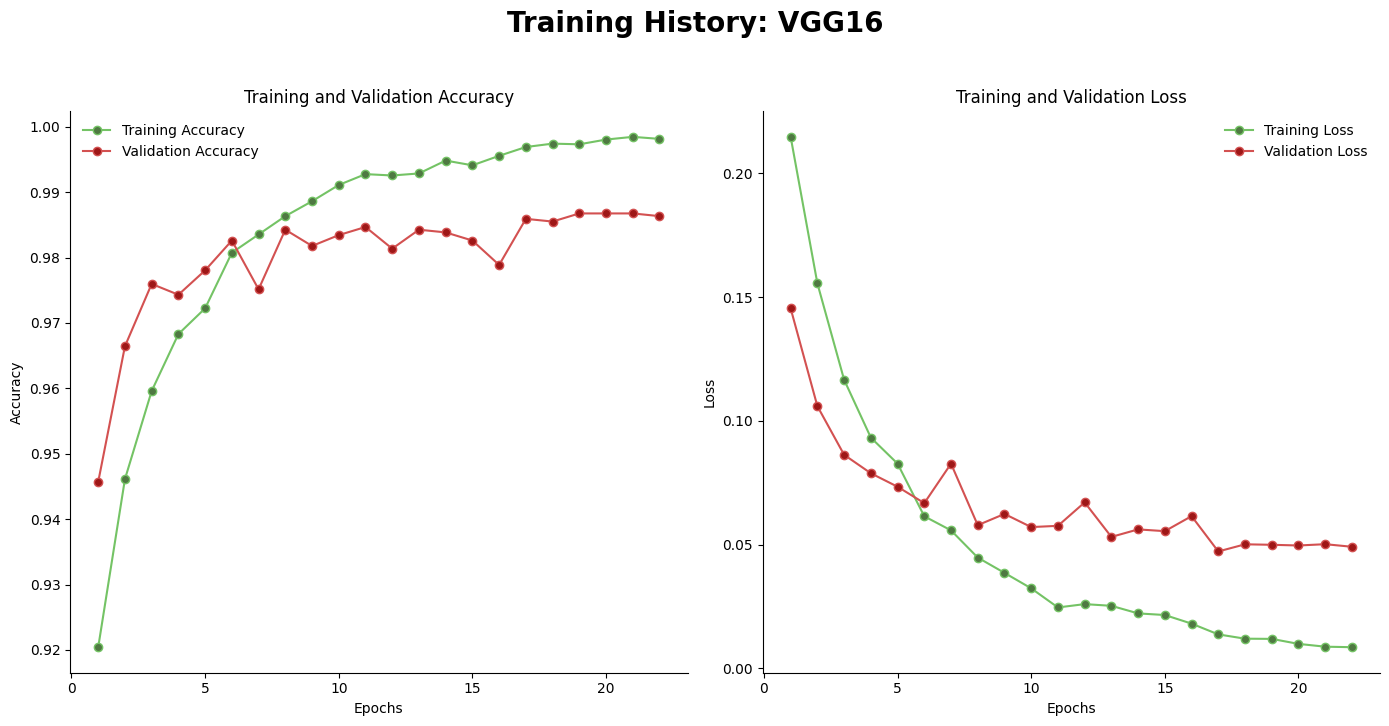

In [ ]:
# Print out traning process:
plot_training_history(history_vgg16, "VGG16")

## 7.3. Evaluate model on test set:

MODEL EVALUATION: VGG16
Test samples                 : 91
Batch size                   : 32
Total inference time         : 3.8436 seconds
Average inference time       : 42.2370 ms/image
Throughput                   : 23.68 images/second
----------------------------------------------------------------------
Accuracy                     : 0.9341
Macro Precision              : 0.8971
Macro Recall                 : 0.9189
Macro F1-score               : 0.8992
Weighted Precision           : 0.9467
Weighted Recall              : 0.9341
Weighted F1-score            : 0.9361
----------------------------------------------------------------------
TUMOR-TO-NO-TUMOR FALSE NEGATIVE RATE
Actual tumor images          : 71
Tumor predicted as notumor     : 0
Tumor FNR                    : 0.0000 (0.00%)
----------------------------------------------------------------------
CLASSIFICATION REPORT
              precision  recall  f1-score  support
glioma           0.9796  0.9796    0.9796  49.0000
meningi

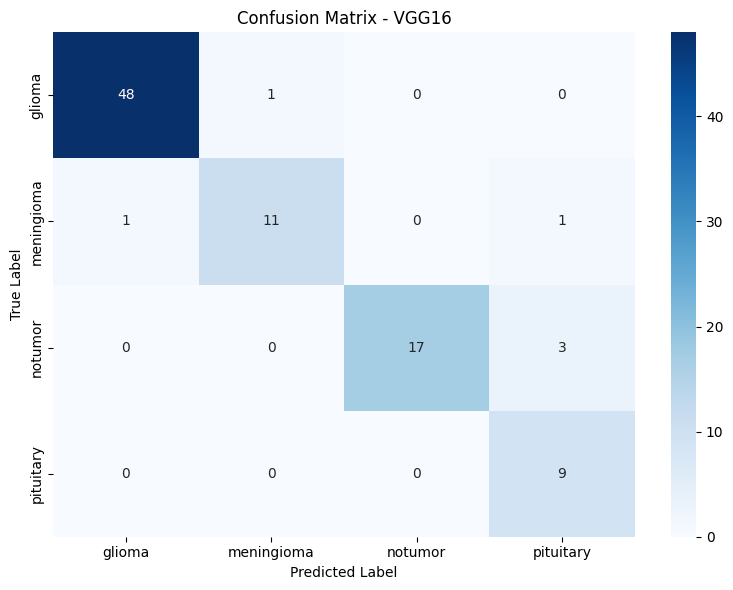

In [ ]:
results_vgg16 = evaluate_model(
    model=vgg16,
    X_test=X_test,
    y_test=y_test,
    model_name="VGG16",
    class_names=CLASS_NAMES,
    no_tumor_label="notumor",
    batch_size=32
)

In [ ]:
# Save model to drive:
vgg16.save("/content/drive/MyDrive/Brain_Tumor_Classification_Project/vgg16_model.keras")
print("Model saved successfully.")

Model saved successfully.


Thus, the model ***VGG16*** achieved **Accuracy = 0.9341**, **Time Inference = 42.2370 ms/image**, and **FNR = 0.0000**!

# 8. Model MobileNetV2:

## 8.1. Load and build model:

In [ ]:
from tensorflow.keras.applications import MobileNetV2

def build_mobilenetv2(input_shape=INPUT_SHAPE, num_classes=4):
    inputs = layers.Input(shape=input_shape)

    mobilenetv2 = MobileNetV2(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    mobilenetv2.trainable = False

    outputs = build_classifier_head(
        mobilenetv2.output,
        num_classes=num_classes
    )

    return Model(inputs, outputs, name="MobileNetV2")

In [ ]:
mobilenetv2 = build_mobilenetv2()
mobilenetv2.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_5[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,587,972 (9.87 MB)

 Trainable params: 329,476 (1.26 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

## 8.2. Fine-tuning model:

In [ ]:
mobilenetv2.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
tensorboard_mobilenetv2 = TensorBoard(
    log_dir='log_mobilenetv2',
)

checkpoint_mobilenetv2 = ModelCheckpoint(
    "mobilenetv2_best.h5",
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

reduce_lr_mobilenetv2 = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_delta=1e-4,
    min_lr=1e-7,
    verbose=1
)

early_stopping_mobilenetv2 = EarlyStopping(
    monitor='val_loss',
    patience=5,
    verbose=1
)

print("Callbacks for MobileNetV2 defined successfully.")

Callbacks for MobileNetV2 defined successfully.


In [ ]:
# Train head:
history_mobilenetv2_head = mobilenetv2.fit(X_train, y_train,
                              validation_data=(X_val, y_val),
                              batch_size=32,
                              epochs=30,
                              verbose=1,
                              callbacks=[tensorboard_mobilenetv2, checkpoint_mobilenetv2, reduce_lr_mobilenetv2, early_stopping_mobilenetv2])

Epoch 1/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.6095 - loss: 1.0712
Epoch 1: val_loss improved from None to 0.56869, saving model to mobilenetv2_best.h5



Epoch 1: finished saving model to mobilenetv2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 36s 85ms/step - accuracy: 0.6766 - loss: 0.8611 - val_accuracy: 0.7837 - val_loss: 0.5687 - learning_rate: 0.0010
Epoch 2/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7381 - loss: 0.6650
Epoch 2: val_loss improved from 0.56869 to 0.48360, saving model to mobilenetv2_best.h5



Epoch 2: finished saving model to mobilenetv2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.7470 - loss: 0.6474 - val_accuracy: 0.8251 - val_loss: 0.4836 - learning_rate: 0.0010
Epoch 3/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7673 - loss: 0.5968
Epoch 3: val_loss improved from 0.48360 to 0.46546, saving model to mobilenetv2_best.h5



Epoch 3: finished saving model to mobilenetv2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.7711 - loss: 0.5865 - val_accuracy: 0.8288 - val_loss: 0.4655 - learning_rate: 0.0010
Epoch 4/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7796 - loss: 0.5543
Epoch 4: val_loss did not improve from 0.46546
302/302 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - accuracy: 0.7790 - loss: 0.5597 - val_accuracy: 0.8052 - val_loss: 0.5051 - learning_rate: 0.0010
Epoch 5/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7861 - loss: 0.5329
Epoch 5: val_loss improved from 0.46546 to 0.42231, saving model to mobilenetv2_best.h5



Epoch 5: finished saving model to mobilenetv2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - accuracy: 0.7893 - loss: 0.5395 - val_accuracy: 0.8508 - val_loss: 0.4223 - learning_rate: 0.0010
Epoch 6/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7964 - loss: 0.5250
Epoch 6: val_loss improved from 0.42231 to 0.41967, saving model to mobilenetv2_best.h5


...


Epoch 26: finished saving model to mobilenetv2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - accuracy: 0.8609 - loss: 0.3625 - val_accuracy: 0.8893 - val_loss: 0.3058 - learning_rate: 2.0000e-04
Epoch 27/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8605 - loss: 0.3568
Epoch 27: val_loss improved from 0.30576 to 0.30410, saving model to mobilenetv2_best.h5



Epoch 27: finished saving model to mobilenetv2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.8612 - loss: 0.3584 - val_accuracy: 0.8902 - val_loss: 0.3041 - learning_rate: 2.0000e-04
Epoch 28/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8571 - loss: 0.3790
Epoch 28: val_loss improved from 0.30410 to 0.30312, saving model to mobilenetv2_best.h5



Epoch 28: finished saving model to mobilenetv2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.8606 - loss: 0.3645 - val_accuracy: 0.8869 - val_loss: 0.3031 - learning_rate: 2.0000e-04
Epoch 29/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8622 - loss: 0.3667
Epoch 29: val_loss improved from 0.30312 to 0.30273, saving model to mobilenetv2_best.h5



Epoch 29: finished saving model to mobilenetv2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.8654 - loss: 0.3545 - val_accuracy: 0.8881 - val_loss: 0.3027 - learning_rate: 2.0000e-04
Epoch 30/30
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8688 - loss: 0.3359
Epoch 30: val_loss improved from 0.30273 to 0.30165, saving model to mobilenetv2_best.h5



Epoch 30: finished saving model to mobilenetv2_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - accuracy: 0.8643 - loss: 0.3502 - val_accuracy: 0.8910 - val_loss: 0.3016 - learning_rate: 2.0000e-04


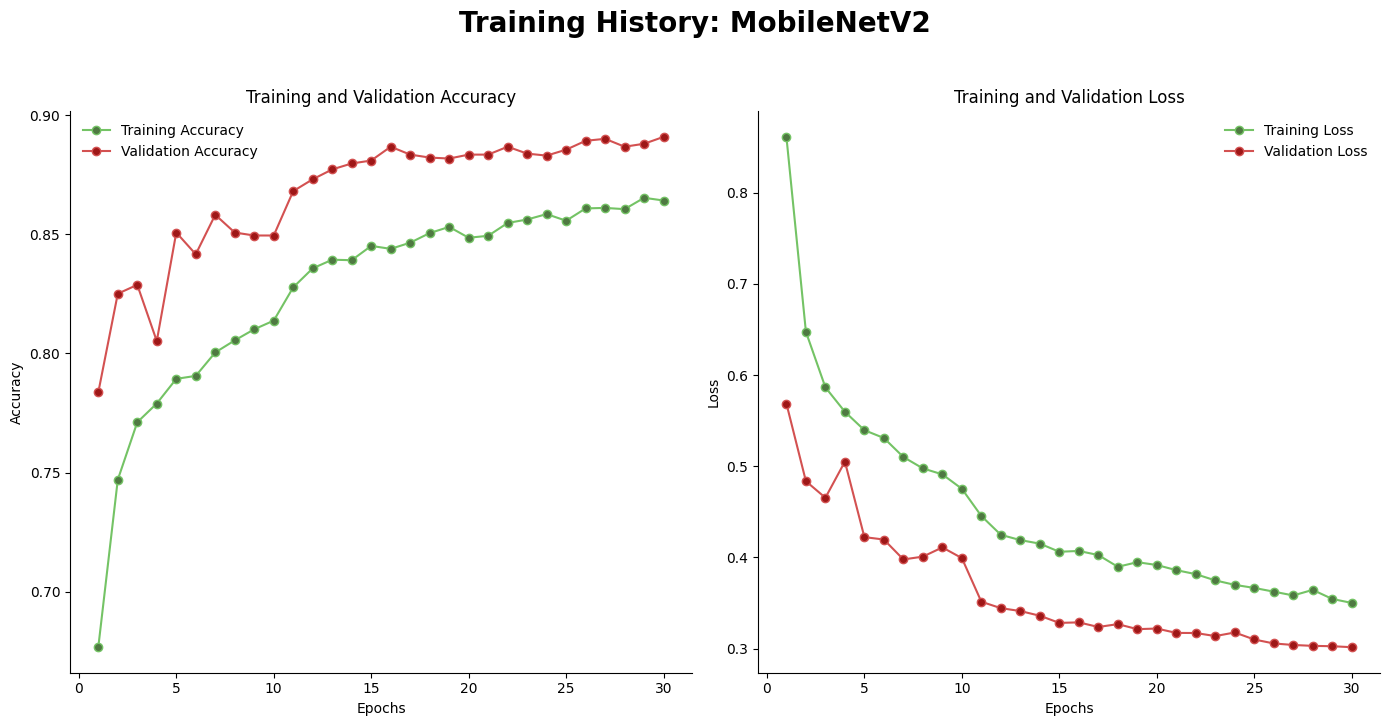

In [ ]:
# Print out traning curve:
plot_training_history(history_mobilenetv2_head, "MobileNetV2")

In [ ]:
# Unfrezed last block to deep finetune:
for layer in mobilenetv2.layers:
    layer.trainable = False
    if "block_16" in layer.name or "Conv_1" in layer.name:
        layer.trainable = True

In [ ]:
mobilenetv2.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history_mobilenetv2_2 = mobilenetv2.fit(X_train, y_train,
                              validation_data=(X_val, y_val),
                              batch_size=32,
                              epochs=25,
                              verbose=1,
                              callbacks=[tensorboard_mobilenetv2, checkpoint_mobilenetv2, reduce_lr_mobilenetv2, early_stopping_mobilenetv2])

Epoch 1/25
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.6813 - loss: 1.1639
Epoch 1: val_loss did not improve from 0.30165
302/302 ━━━━━━━━━━━━━━━━━━━━ 38s 83ms/step - accuracy: 0.7470 - loss: 0.7736 - val_accuracy: 0.2938 - val_loss: 6.9798 - learning_rate: 1.0000e-04
Epoch 2/25
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8389 - loss: 0.4267
Epoch 2: val_loss did not improve from 0.30165
302/302 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - accuracy: 0.8399 - loss: 0.4237 - val_accuracy: 0.5433 - val_loss: 2.3490 - learning_rate: 1.0000e-04
Epoch 3/25
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8668 - loss: 0.3417
Epoch 3: val_loss did not improve from 0.30165

Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.
302/302 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - accuracy: 0.8706 - loss: 0.3366 - val_accuracy: 0.6552 - val_loss: 1.3232 - learning_rate: 1.0000e-04
Epoch 4/25
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9023 - loss:

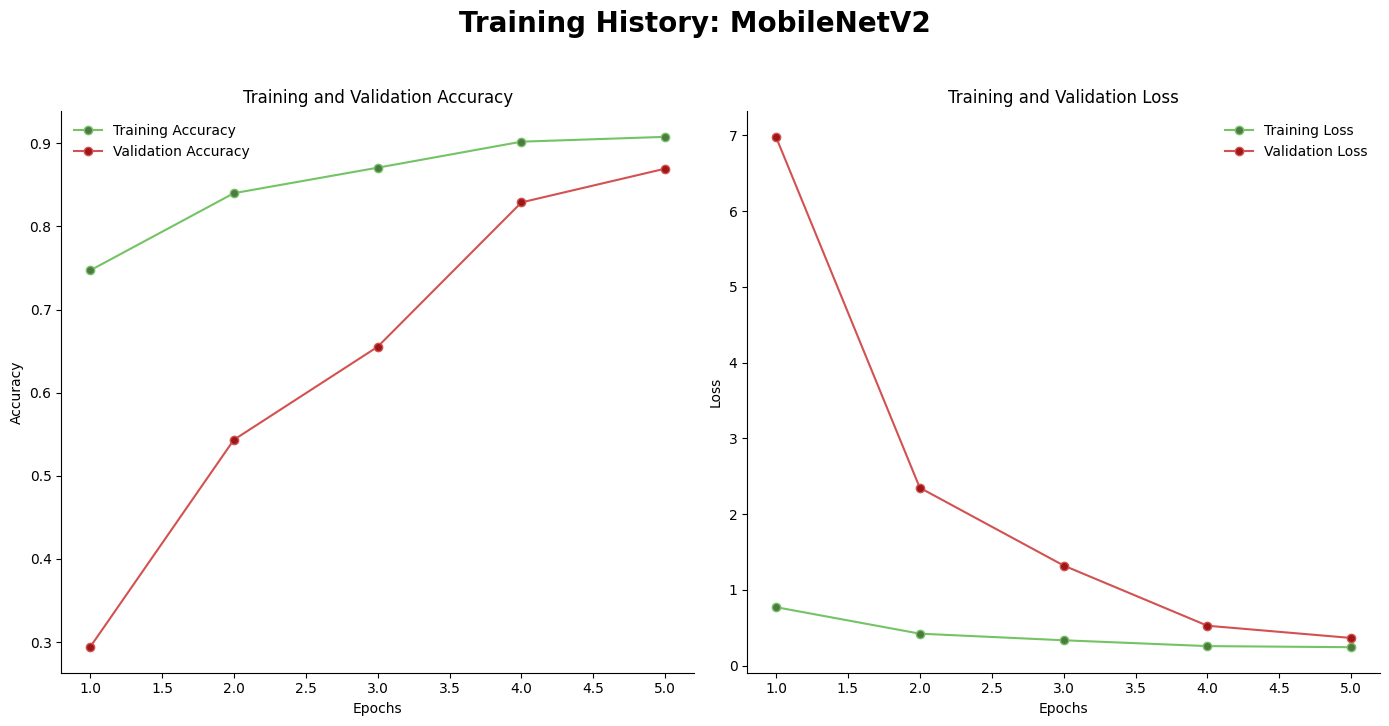

In [ ]:
# Print out training process:
plot_training_history(history_mobilenetv2_2, "MobileNetV2")

## 8.3. Evaluate on test set:

MODEL EVALUATION: MobileNetV2
Test samples                 : 91
Batch size                   : 32
Total inference time         : 4.2101 seconds
Average inference time       : 46.2649 ms/image
Throughput                   : 21.61 images/second
----------------------------------------------------------------------
Accuracy                     : 0.8462
Macro Precision              : 0.8108
Macro Recall                 : 0.7786
Macro F1-score               : 0.7435
Weighted Precision           : 0.9003
Weighted Recall              : 0.8462
Weighted F1-score            : 0.8471
----------------------------------------------------------------------
TUMOR-TO-NO-TUMOR FALSE NEGATIVE RATE
Actual tumor images          : 71
Tumor predicted as notumor     : 0
Tumor FNR                    : 0.0000 (0.00%)
----------------------------------------------------------------------
CLASSIFICATION REPORT
              precision  recall  f1-score  support
glioma           0.9600  0.9796    0.9697  49.0000
m

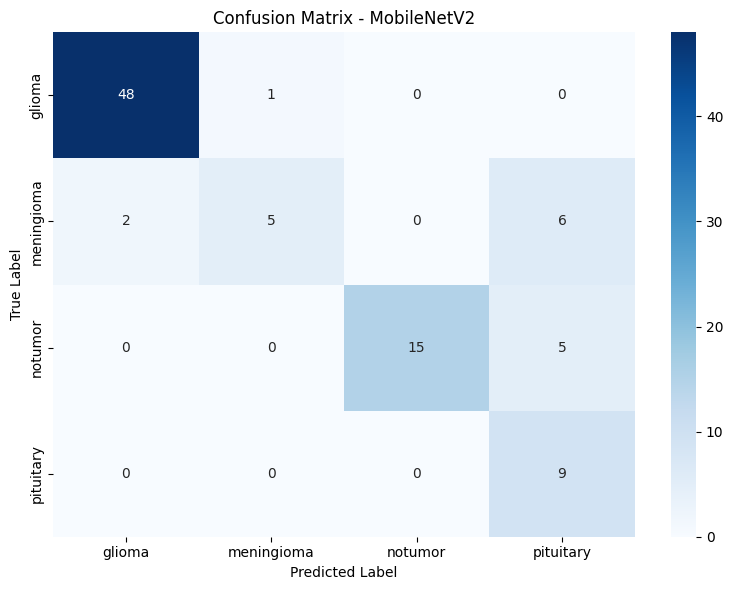

In [ ]:
results_mobilenetv2 = evaluate_model(
    model=mobilenetv2,
    X_test=X_test,
    y_test=y_test,
    model_name="MobileNetV2",
    class_names=CLASS_NAMES,
    no_tumor_label="notumor",
    batch_size=32
)

In [ ]:
# Save the model to drive:
mobilenetv2.save("/content/drive/MyDrive/Brain_Tumor_Classification_Project/mobilenetv2_model.keras")
print("Model saved successfully.")

Model saved successfully.


Thus, the model ***MobileNetV2*** achieved **Accuracy = 0.8462**, **Time Inference = 46.2649 ms/image**, and **FNR = 0.0000**!

# 9. Model ResNet50:

## 9.1. Load and build model:

In [ ]:
from tensorflow.keras.applications import ResNet50

def build_resnet50(input_shape=INPUT_SHAPE, num_classes=4):
    inputs = layers.Input(shape=input_shape)

    resnet50 = ResNet50(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    resnet50.trainable = False

    outputs = build_classifier_head(
        resnet50.output,
        num_classes=num_classes
    )

    return Model(inputs, outputs, name="ResNet50")

In [ ]:
resnet50 = build_resnet50()
resnet50.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_6[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,114,308 (91.99 MB)

 Trainable params: 526,084 (2.01 MB)

 Non-trainable params: 23,588,224 (89.98 MB)

## 9.2. Fine-tuning model:

In [ ]:
resnet50.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
tensorboard_resnet50 = TensorBoard(
    log_dir='log_resnet50',
)

checkpoint_resnet50 = ModelCheckpoint(
    "resnet50_best.h5",
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

reduce_lr_resnet50 = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_delta=1e-4,
    min_lr=1e-7,
    verbose=1
)

early_stopping_resnet50 = EarlyStopping(
    monitor='val_loss',
    patience=5,
    verbose=1
)

print("Callbacks for ResNet50 defined successfully.")

Callbacks for ResNet50 defined successfully.


In [ ]:
history_resnet50_head = resnet50.fit(X_train, y_train,
                              validation_data=(X_val, y_val),
                              batch_size=32,
                              epochs=30,
                              verbose=1,
                              callbacks=[tensorboard_resnet50, checkpoint_resnet50, reduce_lr_resnet50, early_stopping_resnet50])

Epoch 1/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.7420 - loss: 0.7167
Epoch 1: val_loss improved from None to 0.33172, saving model to resnet50_best.h5



Epoch 1: finished saving model to resnet50_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 63s 166ms/step - accuracy: 0.8019 - loss: 0.5380 - val_accuracy: 0.8844 - val_loss: 0.3317 - learning_rate: 0.0010
Epoch 2/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.8629 - loss: 0.3611
Epoch 2: val_loss improved from 0.33172 to 0.24482, saving model to resnet50_best.h5



Epoch 2: finished saving model to resnet50_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 37s 124ms/step - accuracy: 0.8614 - loss: 0.3593 - val_accuracy: 0.9068 - val_loss: 0.2448 - learning_rate: 0.0010
Epoch 3/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.8793 - loss: 0.3245
Epoch 3: val_loss improved from 0.24482 to 0.21134, saving model to resnet50_best.h5



Epoch 3: finished saving model to resnet50_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 39s 128ms/step - accuracy: 0.8814 - loss: 0.3205 - val_accuracy: 0.9254 - val_loss: 0.2113 - learning_rate: 0.0010
Epoch 4/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.8871 - loss: 0.2947
Epoch 4: val_loss improved from 0.21134 to 0.20030, saving model to resnet50_best.h5



Epoch 4: finished saving model to resnet50_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 39s 129ms/step - accuracy: 0.8863 - loss: 0.2971 - val_accuracy: 0.9329 - val_loss: 0.2003 - learning_rate: 0.0010
Epoch 5/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.8987 - loss: 0.2855
Epoch 5: val_loss did not improve from 0.20030
302/302 ━━━━━━━━━━━━━━━━━━━━ 38s 127ms/step - accuracy: 0.8995 - loss: 0.2813 - val_accuracy: 0.9022 - val_loss: 0.2675 - learning_rate: 0.0010
Epoch 6/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.9011 - loss: 0.2566
Epoch 6: val_loss did not improve from 0.20030
302/302 ━━━━━━━━━━━━━━━━━━━━ 39s 128ms/step - accuracy: 0.8951 - loss: 0.2721 - val_accuracy: 0.9213 - val_loss: 0.2232 - learning_rate: 0.0010
Epoch 7/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.9053 - loss: 0.2583
Epoch 7: val_loss did not improve from 0.20030

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
302/302 ━━━━━━━━━━━━━━━━━━━━ 39s 

...


Epoch 22: finished saving model to resnet50_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 41s 136ms/step - accuracy: 0.9450 - loss: 0.1494 - val_accuracy: 0.9598 - val_loss: 0.1137 - learning_rate: 2.0000e-04
Epoch 23/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9404 - loss: 0.1593
Epoch 23: val_loss improved from 0.11370 to 0.11308, saving model to resnet50_best.h5



Epoch 23: finished saving model to resnet50_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 43s 144ms/step - accuracy: 0.9401 - loss: 0.1582 - val_accuracy: 0.9619 - val_loss: 0.1131 - learning_rate: 2.0000e-04
Epoch 24/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9451 - loss: 0.1447
Epoch 24: val_loss did not improve from 0.11308
302/302 ━━━━━━━━━━━━━━━━━━━━ 38s 127ms/step - accuracy: 0.9434 - loss: 0.1510 - val_accuracy: 0.9619 - val_loss: 0.1137 - learning_rate: 2.0000e-04
Epoch 25/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9493 - loss: 0.1366
Epoch 25: val_loss improved from 0.11308 to 0.11093, saving model to resnet50_best.h5



Epoch 25: finished saving model to resnet50_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 47s 157ms/step - accuracy: 0.9485 - loss: 0.1403 - val_accuracy: 0.9606 - val_loss: 0.1109 - learning_rate: 2.0000e-04
Epoch 26/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9452 - loss: 0.1460
Epoch 26: val_loss improved from 0.11093 to 0.10232, saving model to resnet50_best.h5



Epoch 26: finished saving model to resnet50_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 48s 159ms/step - accuracy: 0.9478 - loss: 0.1406 - val_accuracy: 0.9644 - val_loss: 0.1023 - learning_rate: 2.0000e-04
Epoch 27/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9498 - loss: 0.1392
Epoch 27: val_loss did not improve from 0.10232
302/302 ━━━━━━━━━━━━━━━━━━━━ 38s 126ms/step - accuracy: 0.9487 - loss: 0.1427 - val_accuracy: 0.9639 - val_loss: 0.1032 - learning_rate: 2.0000e-04
Epoch 28/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.9550 - loss: 0.1277
Epoch 28: val_loss did not improve from 0.10232
302/302 ━━━━━━━━━━━━━━━━━━━━ 38s 128ms/step - accuracy: 0.9495 - loss: 0.1374 - val_accuracy: 0.9648 - val_loss: 0.1072 - learning_rate: 2.0000e-04
Epoch 29/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9514 - loss: 0.1355
Epoch 29: val_loss improved from 0.10232 to 0.09676, saving model to resnet50_best.h5



Epoch 29: finished saving model to resnet50_best.h5
302/302 ━━━━━━━━━━━━━━━━━━━━ 44s 146ms/step - accuracy: 0.9507 - loss: 0.1312 - val_accuracy: 0.9702 - val_loss: 0.0968 - learning_rate: 2.0000e-04
Epoch 30/30
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9503 - loss: 0.1295
Epoch 30: val_loss did not improve from 0.09676
302/302 ━━━━━━━━━━━━━━━━━━━━ 38s 127ms/step - accuracy: 0.9524 - loss: 0.1268 - val_accuracy: 0.9660 - val_loss: 0.0999 - learning_rate: 2.0000e-04


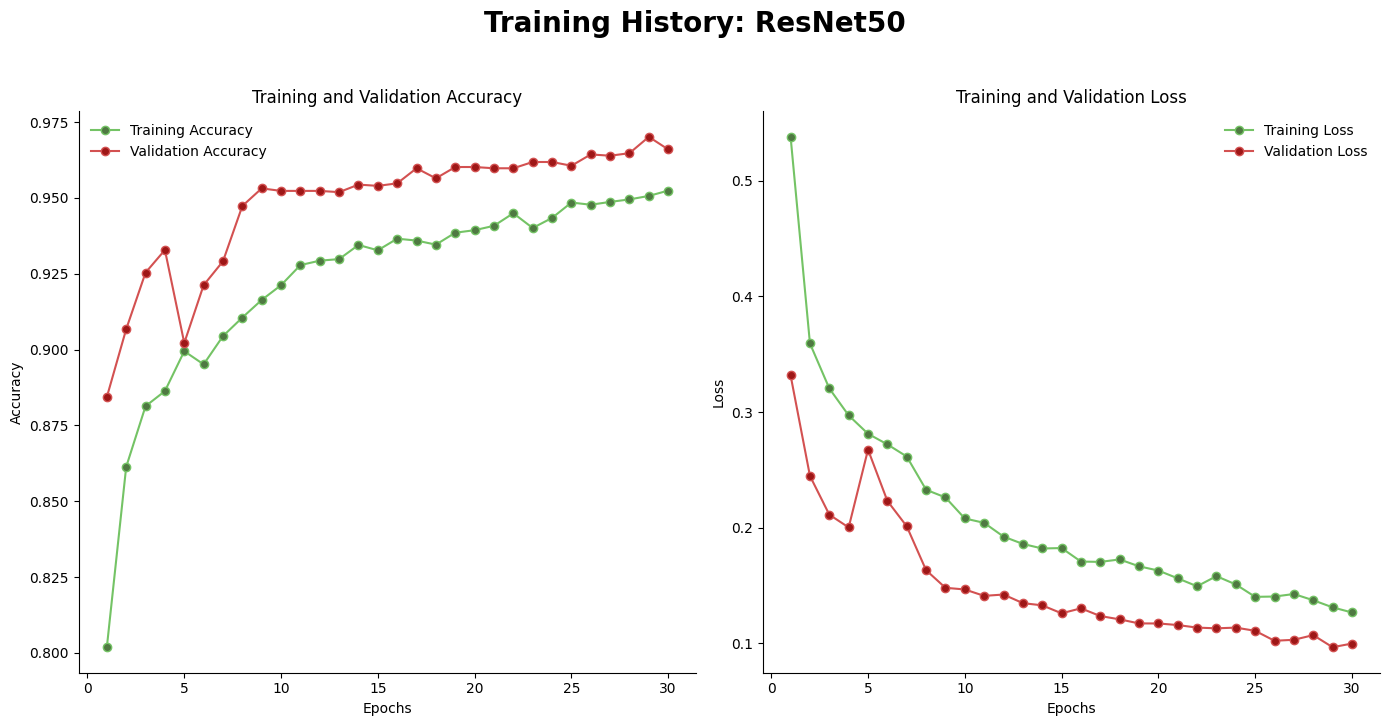

In [ ]:
# Print out training process:
plot_training_history(history_resnet50_head, "ResNet50")

## 9.3. Evaluate model on test set:

MODEL EVALUATION: ResNet50
Test samples                 : 91
Batch size                   : 32
Total inference time         : 5.3497 seconds
Average inference time       : 58.7876 ms/image
Throughput                   : 17.01 images/second
----------------------------------------------------------------------
Accuracy                     : 0.9670
Macro Precision              : 0.9531
Macro Recall                 : 0.9847
Macro F1-score               : 0.9662
Weighted Precision           : 0.9732
Weighted Recall              : 0.9670
Weighted F1-score            : 0.9682
----------------------------------------------------------------------
TUMOR-TO-NO-TUMOR FALSE NEGATIVE RATE
Actual tumor images          : 71
Tumor predicted as notumor     : 0
Tumor FNR                    : 0.0000 (0.00%)
----------------------------------------------------------------------
CLASSIFICATION REPORT
              precision  recall  f1-score  support
glioma           1.0000  0.9388    0.9684   49.000
meni

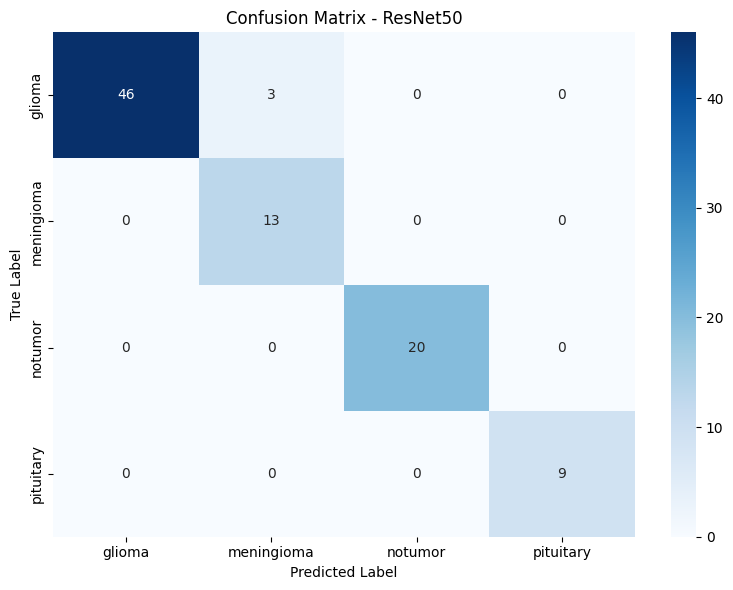

In [ ]:
results_resnet50 = evaluate_model(
    model=resnet50,
    X_test=X_test,
    y_test=y_test,
    model_name="ResNet50",
    class_names=CLASS_NAMES,
    no_tumor_label="notumor",
    batch_size=32
)

In [ ]:
# Save model to drive:
resnet50.save("/content/drive/MyDrive/Brain_Tumor_Classification_Project/resnet50_model.keras")
print("Model saved successfully.")

Model saved successfully.


Thus, the model ***ResNet50*** achieved **Accuracy = 0.9670**, **Time Inference = 58.7876 ms/image**, and **FNR = 0.0000**!